In [3]:
import pandas as pd
import seaborn as sns
import matplotlib
matplotlib.use("Agg") 
%matplotlib inline
import matplotlib.pyplot as plt
import argparse  
import sqlite3
from threading import Thread

cnx = sqlite3.connect('../data.db')
try:
    cnx.execute('''
            CREATE INDEX IF NOT EXISTS idx_elasticity_lookup 
            ON data (experiment, provider, date_time, language, cpu, memory, timestamp)
    ''')
    cnx.commit()
    print("Index created/verified")
except Exception as e:
    print(f"Index creation note: {e}")

Index created/verified


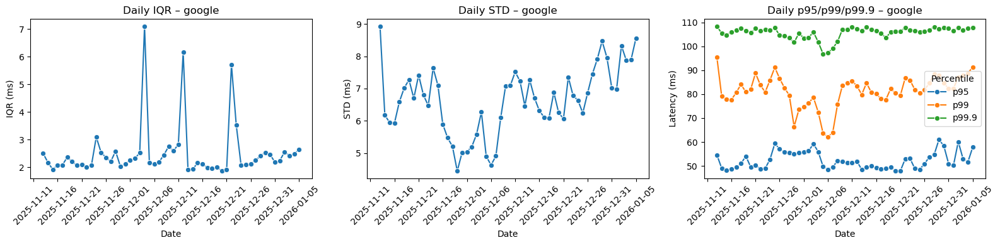

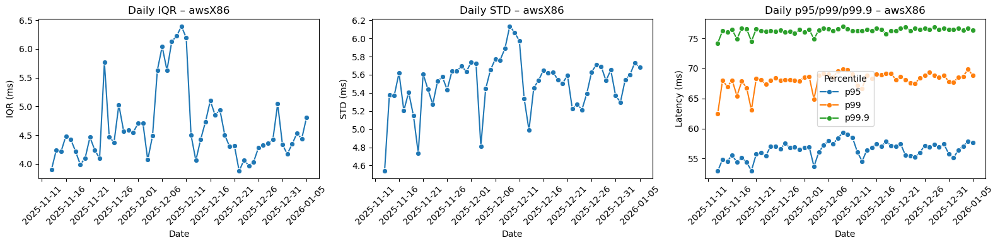

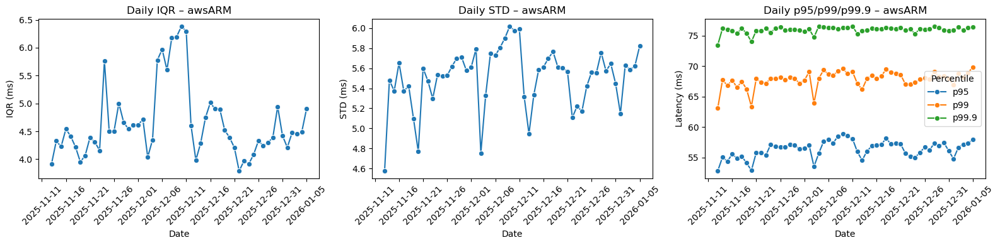

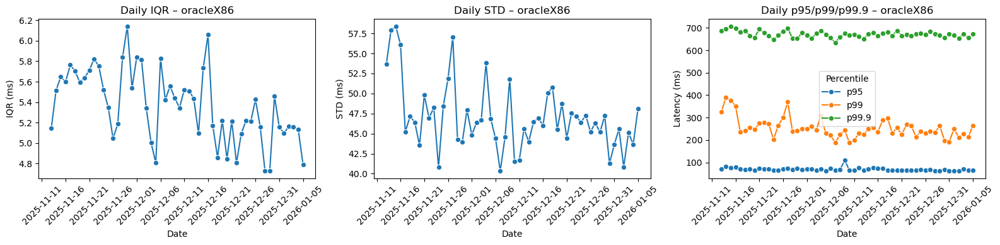

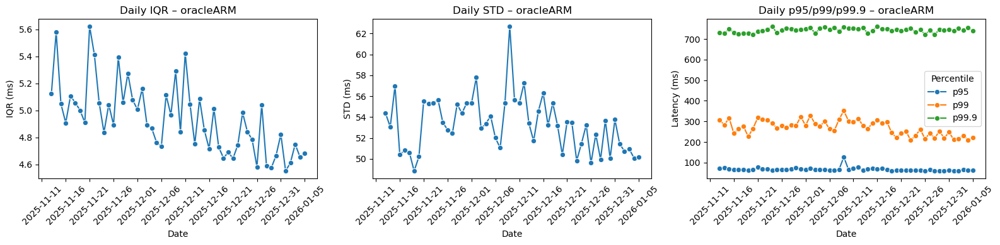

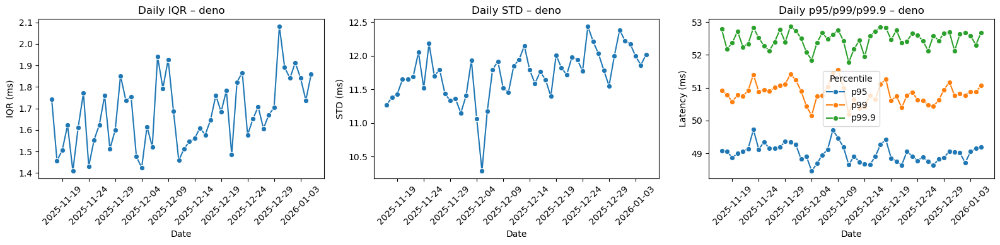

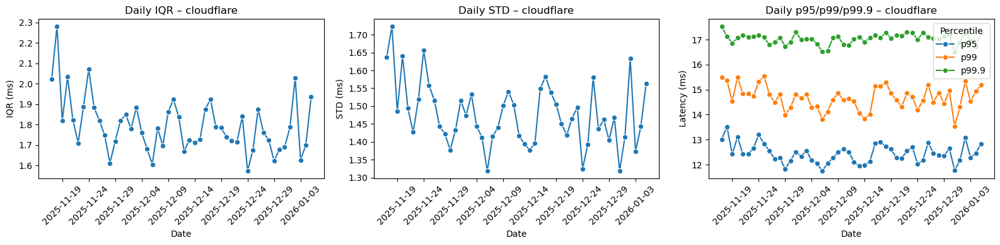

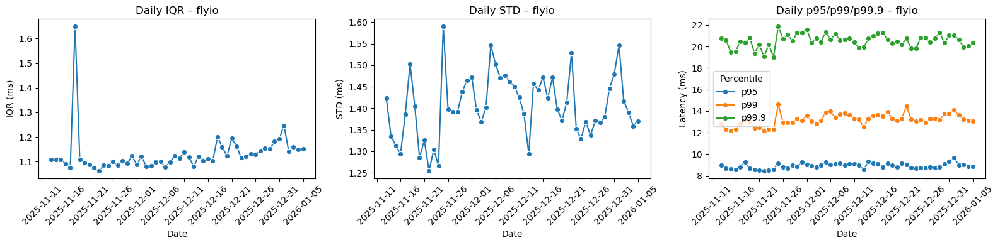

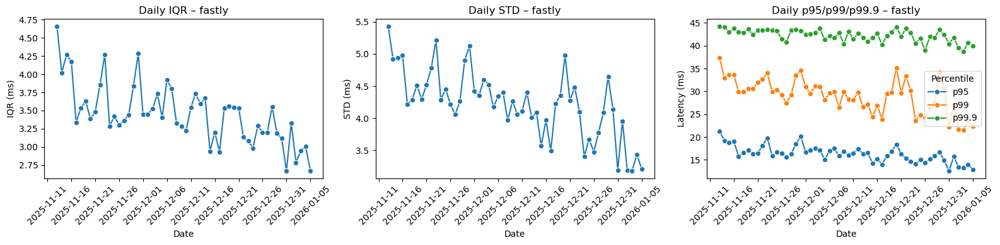

In [2]:
# WARM

# Daily IQR, STD, and p95/p99/p99.9 of warmstart latency per provider (side-by-side, no shared y-axis)
import matplotlib.dates as mdates

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

for provider in providers:
    if provider == "fastly":
        df_provider = pd.read_sql_query(
            """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
            """,
            cnx,
            params=[provider],
        )
    else:
        df_provider = pd.read_sql_query(
            """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
            """,
            cnx,
            params=[provider],
        )
    if df_provider.empty:
        continue

    df_provider["date_time"] = df_provider["date_time"].str[:10]
    p99 = df_provider["http_req_waiting"].quantile(0.99)
    df_provider = df_provider[df_provider["http_req_waiting"] <= p99]

    daily_stats = (
        df_provider.groupby("date_time", as_index=False)["http_req_waiting"]
        .agg(
            p25=lambda s: s.quantile(0.25),
            p75=lambda s: s.quantile(0.75),
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            std="std",
        )
    )
    daily_stats["iqr"] = daily_stats["p75"] - daily_stats["p25"]
    daily_stats["date"] = pd.to_datetime(daily_stats["date_time"], errors="coerce")
    daily_stats = daily_stats.dropna(subset=["date"])

    fig, (ax_iqr, ax_std, ax_p) = plt.subplots(1, 3, figsize=(16, 4), sharey=False)

    sns.lineplot(
        data=daily_stats,
        x="date",
        y="iqr",
        ax=ax_iqr,
        marker="o",
    )
    ax_iqr.set_title(f"Daily IQR – {provider}")
    ax_iqr.set_xlabel("Date")
    ax_iqr.set_ylabel("IQR (ms)")
    ax_iqr.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax_iqr.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_iqr.tick_params(axis="x", rotation=45)

    sns.lineplot(
        data=daily_stats,
        x="date",
        y="std",
        ax=ax_std,
        marker="o",
    )
    ax_std.set_title(f"Daily STD – {provider}")
    ax_std.set_xlabel("Date")
    ax_std.set_ylabel("STD (ms)")
    ax_std.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax_std.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_std.tick_params(axis="x", rotation=45)

    sns.lineplot(
        data=daily_stats,
        x="date",
        y="p95",
        ax=ax_p,
        marker="o",
        label="p95",
    )
    sns.lineplot(
        data=daily_stats,
        x="date",
        y="p99",
        ax=ax_p,
        marker="o",
        label="p99",
    )
    sns.lineplot(
        data=daily_stats,
        x="date",
        y="p999",
        ax=ax_p,
        marker="o",
        label="p99.9",
    )
    ax_p.set_title(f"Daily p95/p99/p99.9 – {provider}")
    ax_p.set_xlabel("Date")
    ax_p.set_ylabel("Latency (ms)")
    ax_p.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_p.tick_params(axis="x", rotation=45)
    ax_p.legend(title="Percentile")

    plt.tight_layout()
    plt.show()

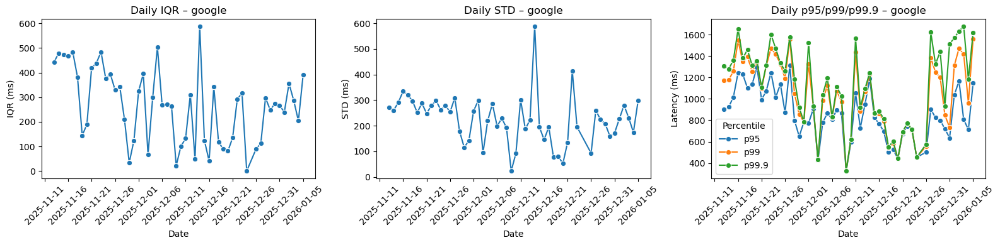

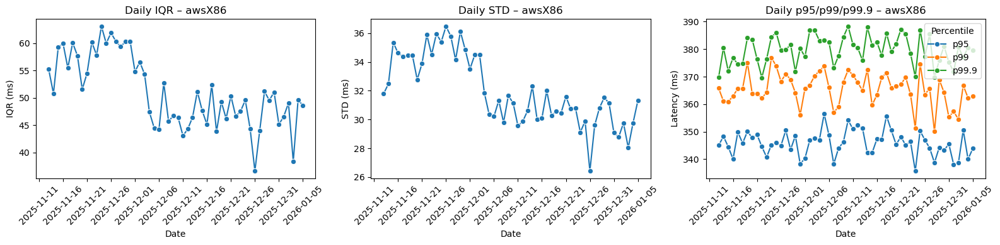

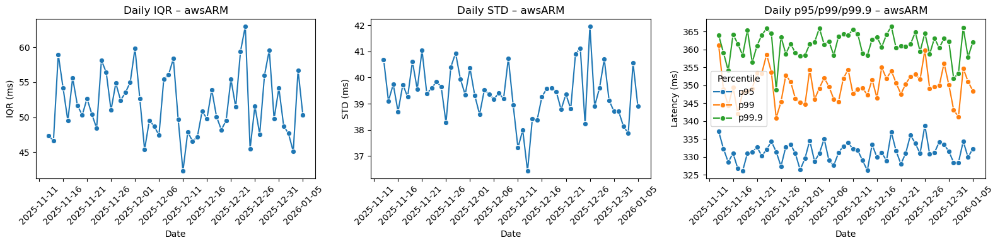

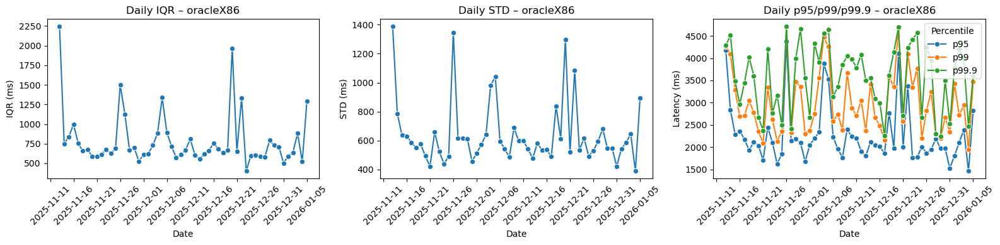

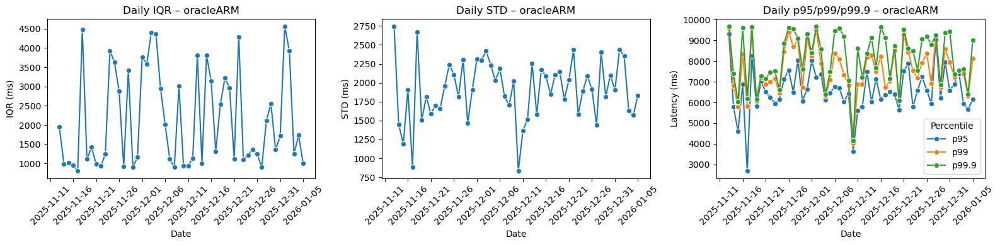

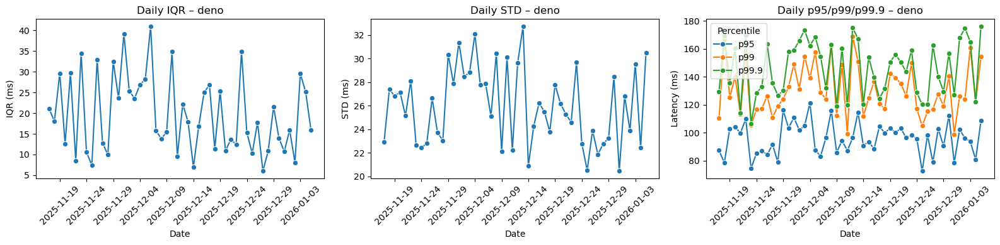

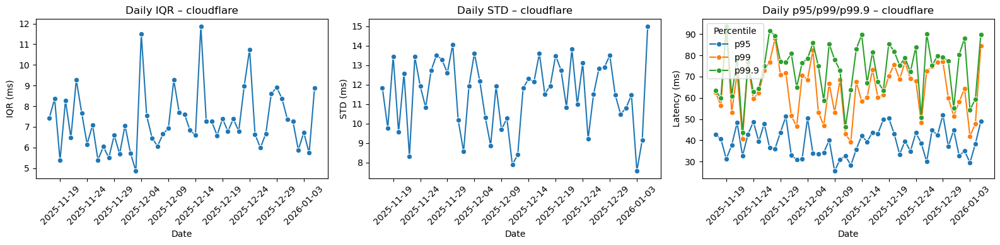

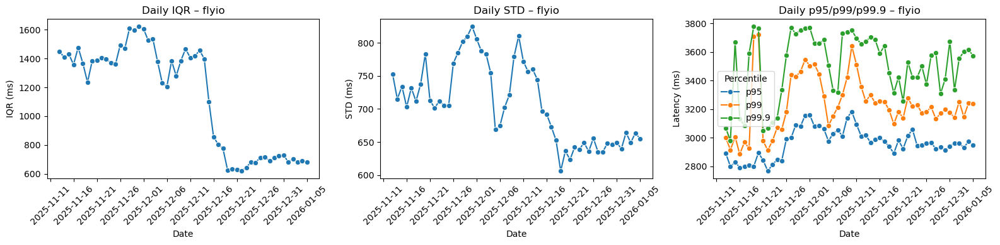

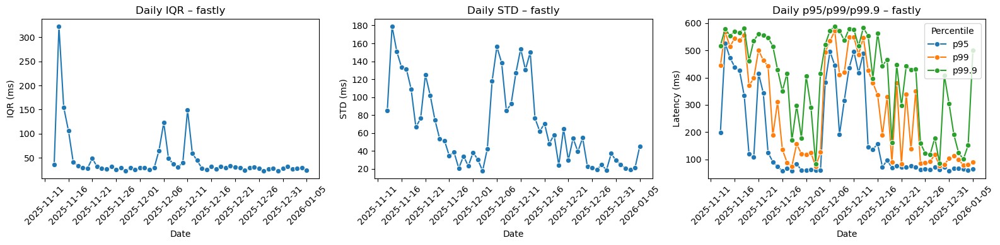

In [3]:
# COLD

# Daily IQR, STD, and p95/p99/p99.9 of coldstart latency per provider (side-by-side, no shared y-axis)
import matplotlib.dates as mdates

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

for provider in providers:
    df_provider = pd.read_sql_query(
        """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
        """,
        cnx,
        params=[provider],
    )
    if df_provider.empty:
        continue

    df_provider["date_time"] = df_provider["date_time"].str[:10]
    p99 = df_provider["http_req_waiting"].quantile(0.99)
    df_provider = df_provider[df_provider["http_req_waiting"] <= p99]

    daily_stats = (
        df_provider.groupby("date_time", as_index=False)["http_req_waiting"]
        .agg(
            p25=lambda s: s.quantile(0.25),
            p75=lambda s: s.quantile(0.75),
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            std="std",
        )
    )
    daily_stats["iqr"] = daily_stats["p75"] - daily_stats["p25"]
    daily_stats["date"] = pd.to_datetime(daily_stats["date_time"], errors="coerce")
    daily_stats = daily_stats.dropna(subset=["date"])

    fig, (ax_iqr, ax_std, ax_p) = plt.subplots(1, 3, figsize=(16, 4), sharey=False)

    sns.lineplot(
        data=daily_stats,
        x="date",
        y="iqr",
        ax=ax_iqr,
        marker="o",
    )
    ax_iqr.set_title(f"Daily IQR – {provider}")
    ax_iqr.set_xlabel("Date")
    ax_iqr.set_ylabel("IQR (ms)")
    ax_iqr.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax_iqr.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_iqr.tick_params(axis="x", rotation=45)

    sns.lineplot(
        data=daily_stats,
        x="date",
        y="std",
        ax=ax_std,
        marker="o",
    )
    ax_std.set_title(f"Daily STD – {provider}")
    ax_std.set_xlabel("Date")
    ax_std.set_ylabel("STD (ms)")
    ax_std.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax_std.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_std.tick_params(axis="x", rotation=45)

    sns.lineplot(
        data=daily_stats,
        x="date",
        y="p95",
        ax=ax_p,
        marker="o",
        label="p95",
    )
    sns.lineplot(
        data=daily_stats,
        x="date",
        y="p99",
        ax=ax_p,
        marker="o",
        label="p99",
    )
    sns.lineplot(
        data=daily_stats,
        x="date",
        y="p999",
        ax=ax_p,
        marker="o",
        label="p99.9",
    )
    ax_p.set_title(f"Daily p95/p99/p99.9 – {provider}")
    ax_p.set_xlabel("Date")
    ax_p.set_ylabel("Latency (ms)")
    ax_p.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_p.tick_params(axis="x", rotation=45)
    ax_p.legend(title="Percentile")

    plt.tight_layout()
    plt.show()

Warmstart KDE | google | go | n=959761
Warmstart ECDF | google | go | n=959761
Warmstart KDE | google | js | n=959599
Warmstart ECDF | google | js | n=959599


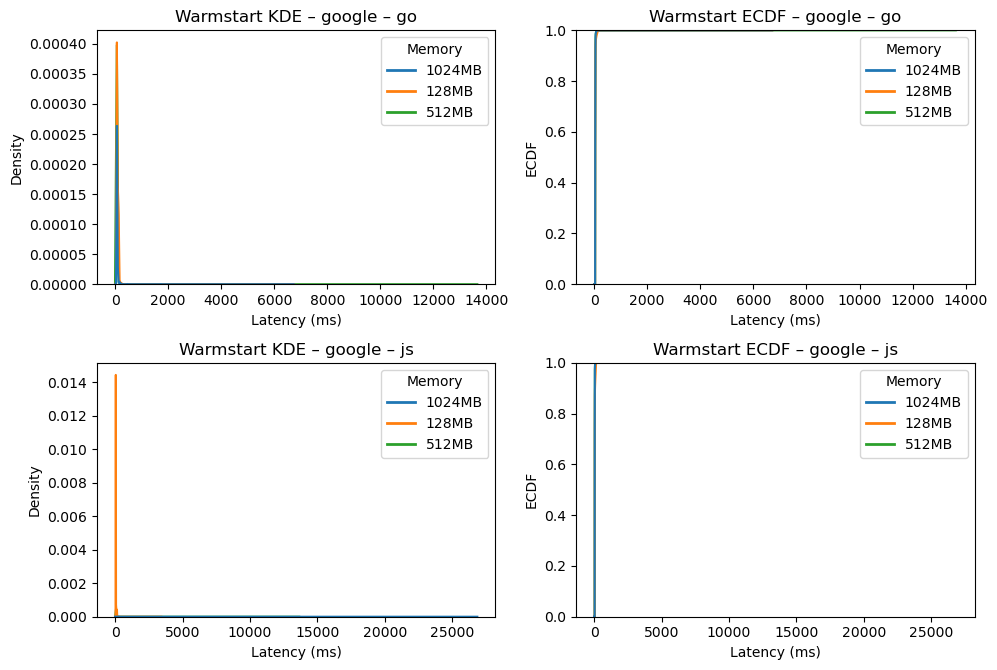

Warmstart KDE | awsX86 | go | n=661391
Warmstart ECDF | awsX86 | go | n=661391
Warmstart KDE | awsX86 | js | n=957353
Warmstart ECDF | awsX86 | js | n=957353


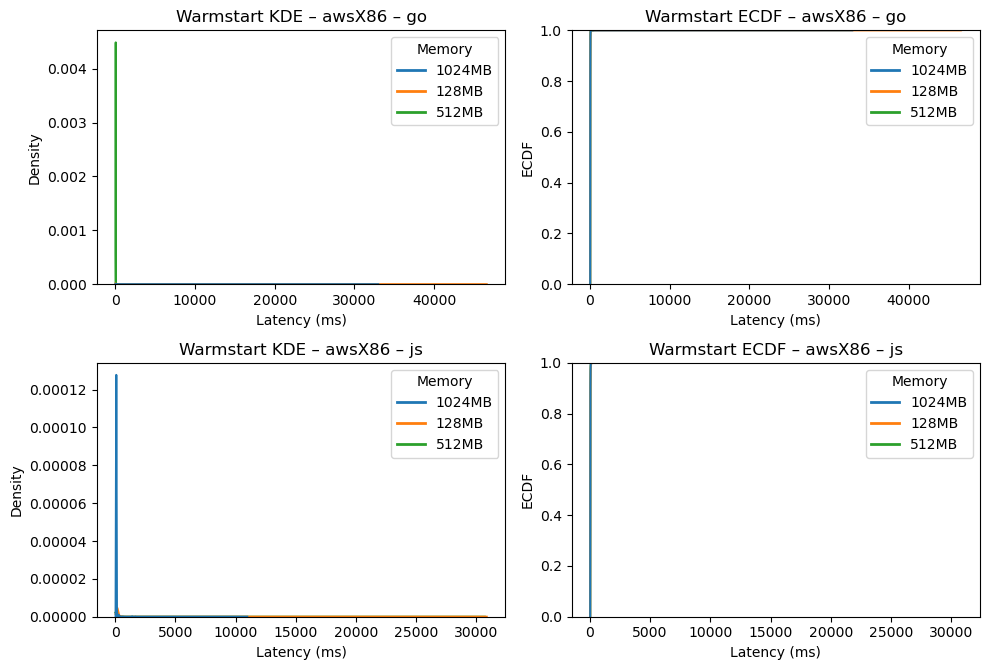

Warmstart KDE | awsARM | go | n=957861
Warmstart ECDF | awsARM | go | n=957861
Warmstart KDE | awsARM | js | n=957644
Warmstart ECDF | awsARM | js | n=957644


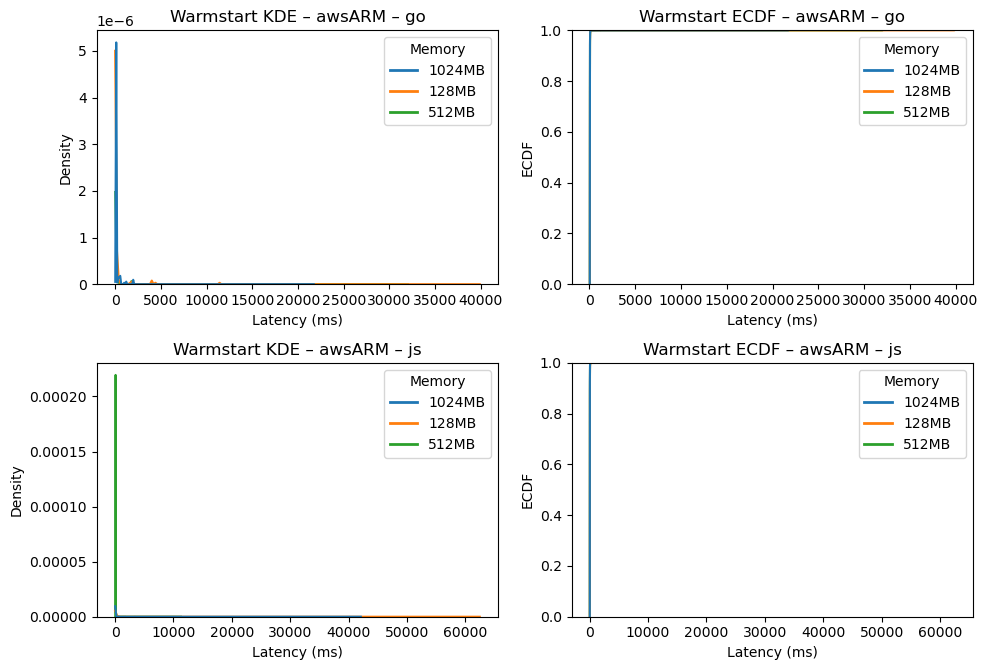

Warmstart KDE | oracleX86 | go | n=923372
Warmstart ECDF | oracleX86 | go | n=923372
Warmstart KDE | oracleX86 | js | n=924914
Warmstart ECDF | oracleX86 | js | n=924914


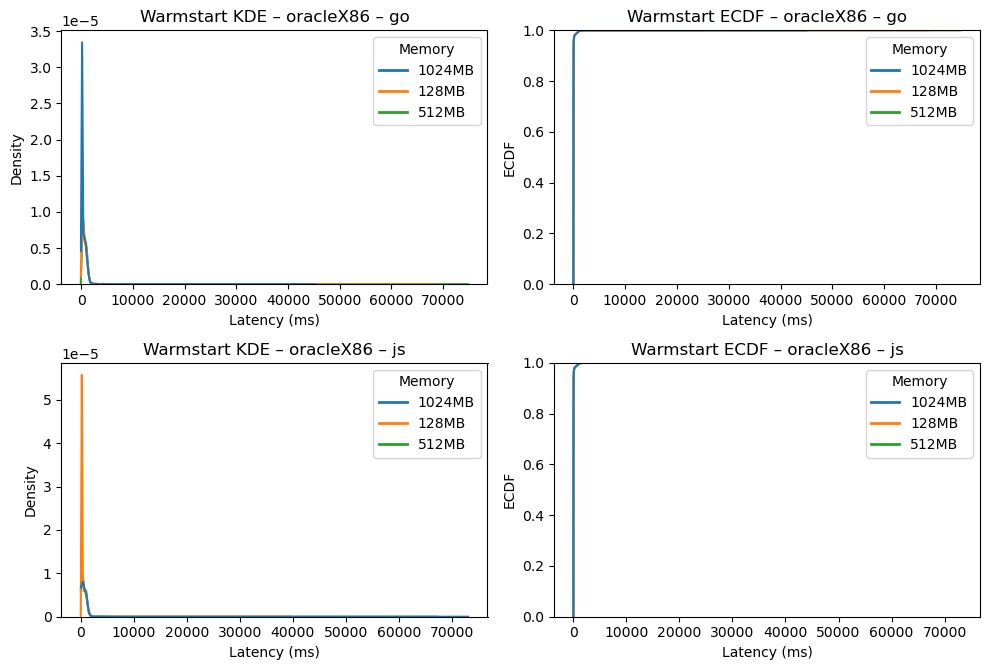

Warmstart KDE | oracleARM | go | n=943106
Warmstart ECDF | oracleARM | go | n=943106
Warmstart KDE | oracleARM | js | n=942950
Warmstart ECDF | oracleARM | js | n=942950


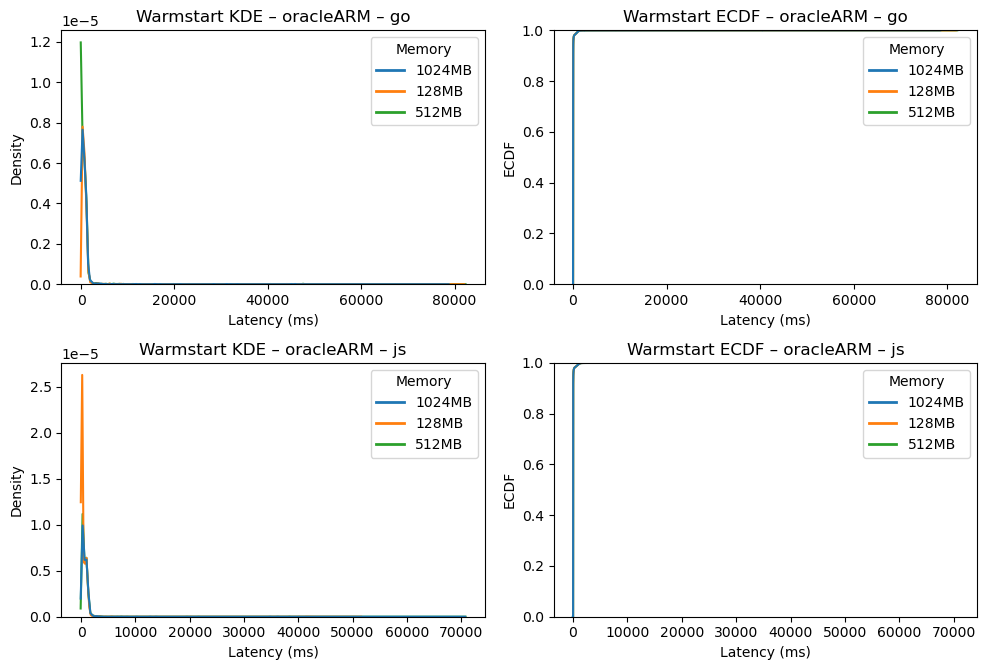

Warmstart KDE | deno | js | n=293184
Warmstart ECDF | deno | js | n=293184


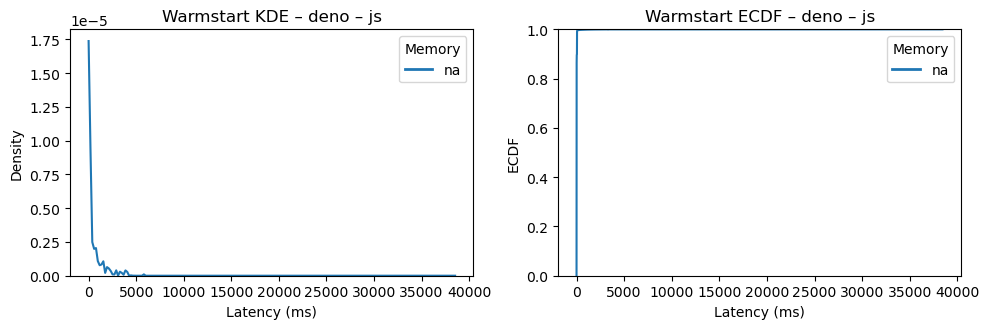

Warmstart KDE | cloudflare | js | n=278482
Warmstart ECDF | cloudflare | js | n=278482


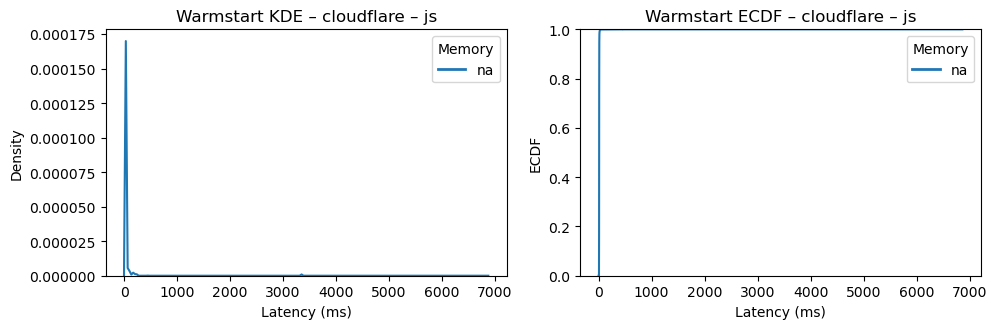

Warmstart KDE | flyio | go | n=937762
Warmstart ECDF | flyio | go | n=937762
Warmstart KDE | flyio | js | n=935763
Warmstart ECDF | flyio | js | n=935763


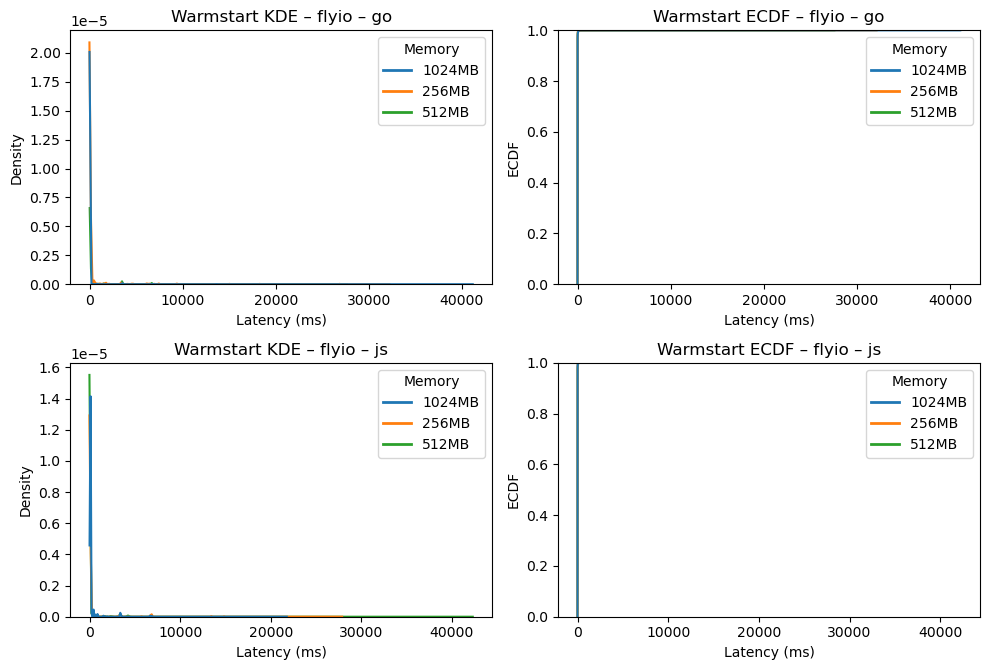

Warmstart KDE | fastly | go | n=320083
Warmstart ECDF | fastly | go | n=320083
Warmstart KDE | fastly | js | n=320073
Warmstart ECDF | fastly | js | n=320073


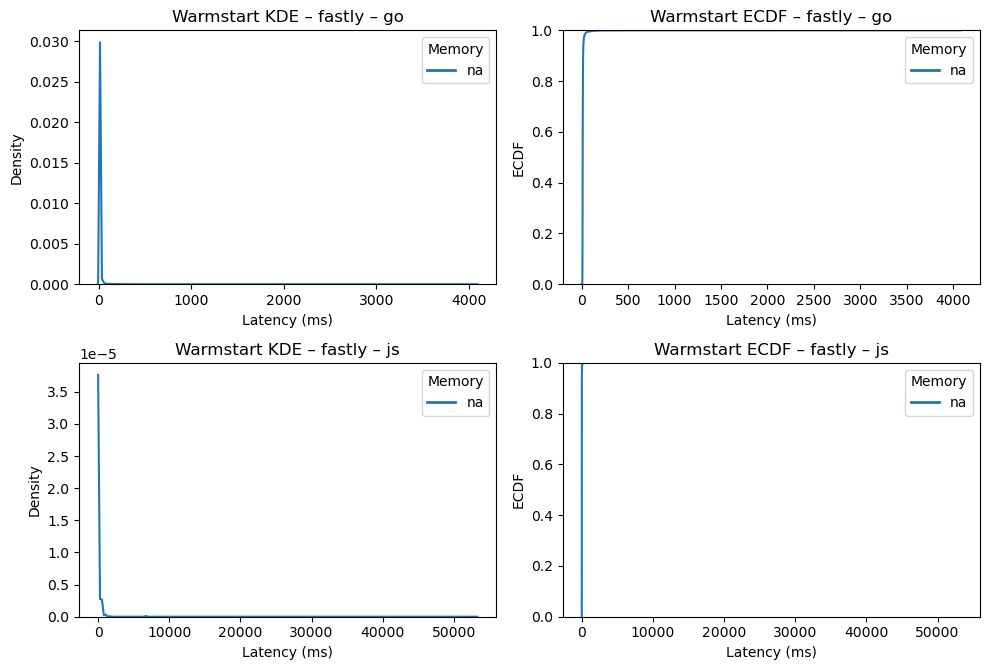

In [3]:
 # KDE + ECDF plots of warmstart latency per provider, split by language and memory
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

for provider in providers:
    if provider == "fastly":
        df_provider = pd.read_sql_query(
            """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
            """,
            cnx,
            params=[provider],
        )
    else:
        df_provider = pd.read_sql_query(
            """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
            """,
            cnx,
            params=[provider],
        )
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider = df_provider.dropna(subset=["http_req_waiting", "language", "memory"])
    if df_provider.empty:
        continue

    df_provider["language"] = df_provider["language"].astype(str).str.lower()
    df_provider["memory"] = df_provider["memory"].astype(str)

    memory_order = sorted(df_provider["memory"].unique())
    palette = sns.color_palette("tab10", n_colors=len(memory_order))
    palette_map = {mem: color for mem, color in zip(memory_order, palette)}

    languages = sorted(df_provider["language"].unique())
    n_lang = len(languages)
    fig, axes = plt.subplots(nrows=n_lang, ncols=2, figsize=(10, 3.4 * n_lang), sharex=False)
    if n_lang == 1:
        axes = [axes]

    for row_axes, lang in zip(axes, languages):
        ax_kde, ax_ecdf = row_axes
        df_lang = df_provider[df_provider["language"] == lang]
        if df_lang.empty:
            ax_kde.set_visible(False)
            ax_ecdf.set_visible(False)
            continue
        print(f"Warmstart KDE | {provider} | {lang} | n={len(df_lang)}")
        sns.kdeplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            fill=False,
            bw_adjust=1.0,
            ax=ax_kde,
        )
        ax_kde.set_title(f"Warmstart KDE – {provider} – {lang}")
        ax_kde.set_xlabel("Latency (ms)")
        ax_kde.set_ylabel("Density")

        handles, labels = ax_kde.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_kde.legend(handles, labels, title="Memory", loc="best")

        print(f"Warmstart ECDF | {provider} | {lang} | n={len(df_lang)}")
        sns.ecdfplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            ax=ax_ecdf,
        )
        ax_ecdf.set_title(f"Warmstart ECDF – {provider} – {lang}")
        ax_ecdf.set_xlabel("Latency (ms)")
        ax_ecdf.set_ylabel("ECDF")

        handles, labels = ax_ecdf.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_ecdf.legend(handles, labels, title="Memory", loc="best")

    plt.tight_layout()
    plt.show()

Coldstart KDE | google | go | n=1354
Coldstart ECDF | google | go | n=1354
Coldstart KDE | google | js | n=1072
Coldstart ECDF | google | js | n=1072


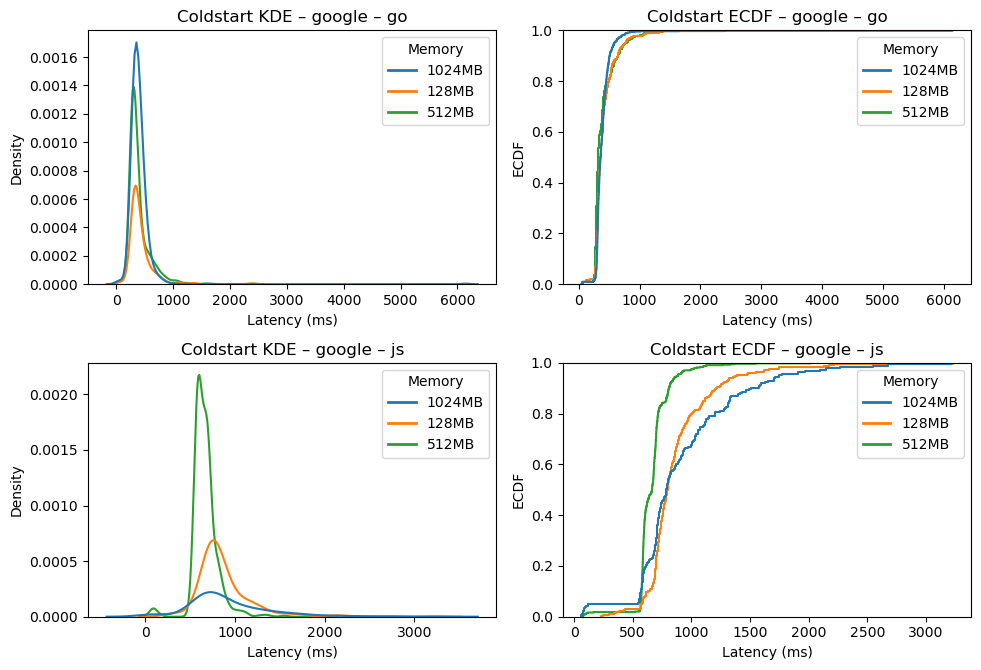

Coldstart KDE | awsX86 | go | n=12791
Coldstart ECDF | awsX86 | go | n=12791
Coldstart KDE | awsX86 | js | n=12679
Coldstart ECDF | awsX86 | js | n=12679


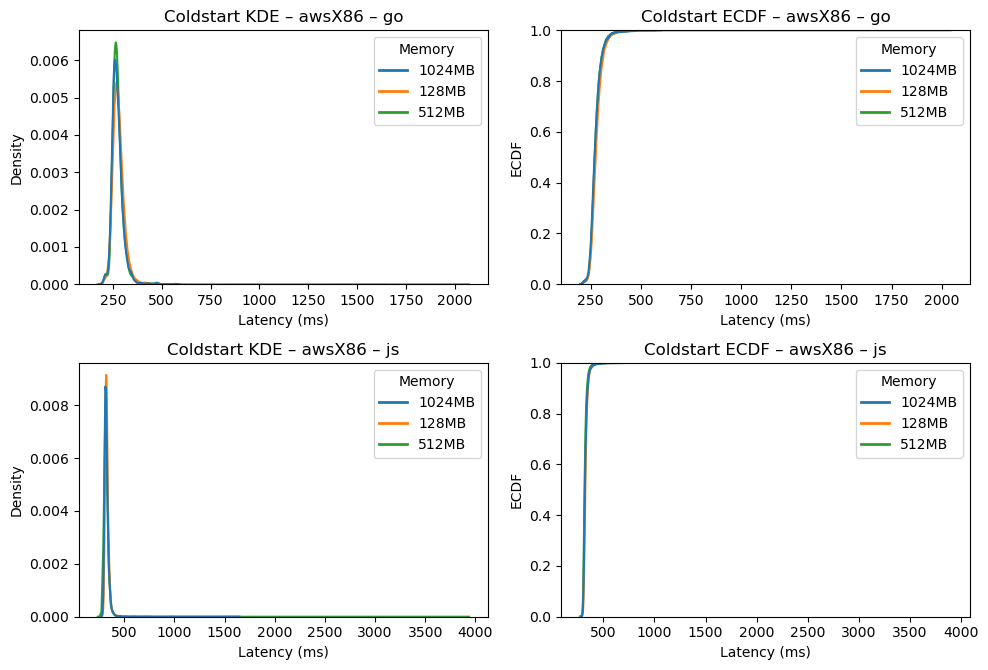

Coldstart KDE | awsARM | go | n=14259
Coldstart ECDF | awsARM | go | n=14259
Coldstart KDE | awsARM | js | n=14130
Coldstart ECDF | awsARM | js | n=14130


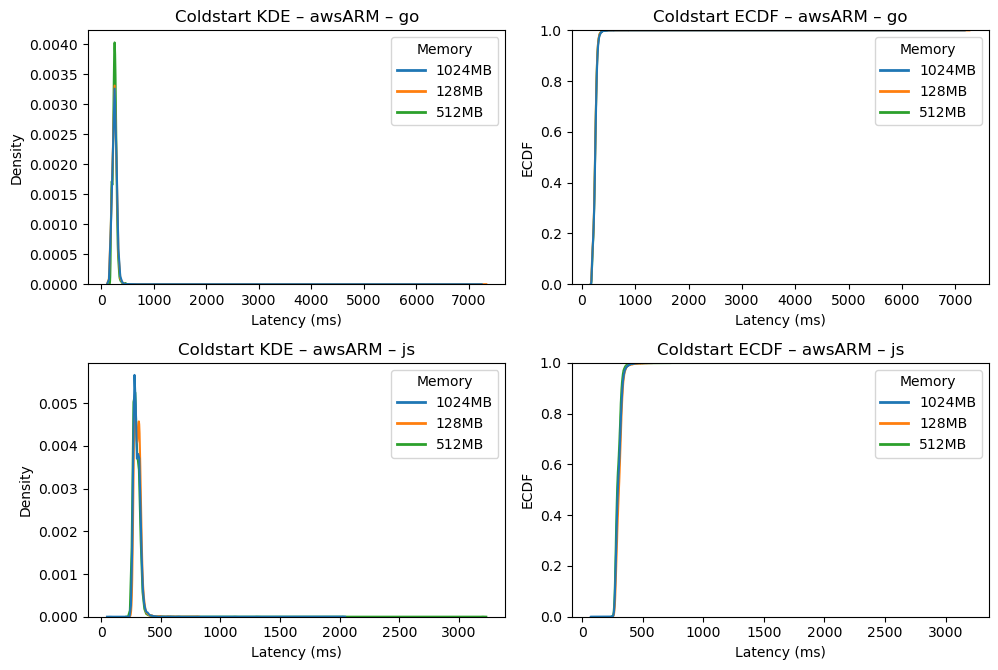

Coldstart KDE | oracleX86 | go | n=9042
Coldstart ECDF | oracleX86 | go | n=9042
Coldstart KDE | oracleX86 | js | n=9025
Coldstart ECDF | oracleX86 | js | n=9025


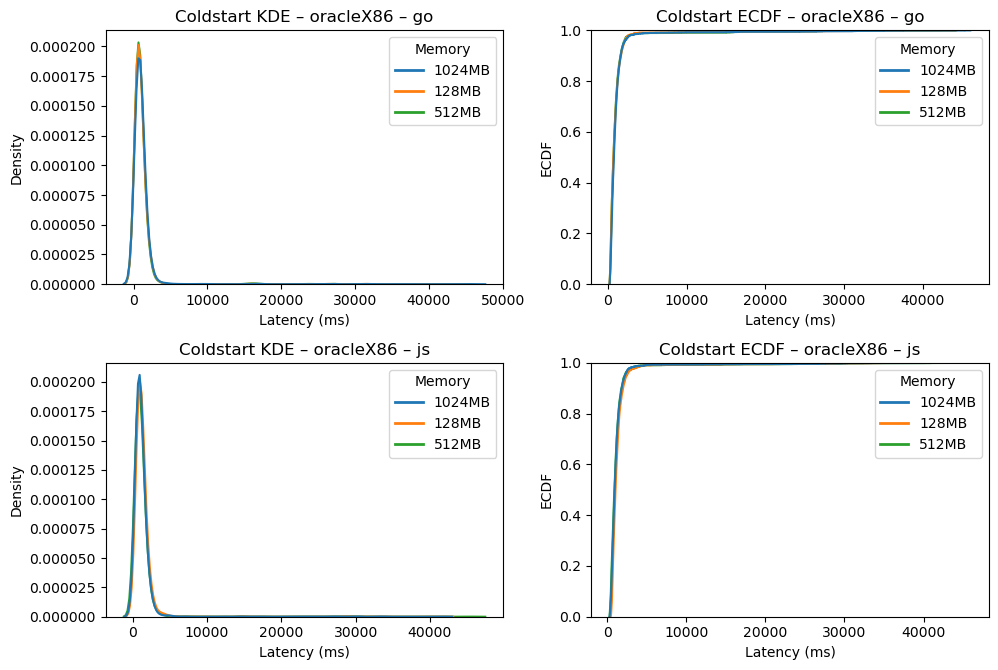

Coldstart KDE | oracleARM | go | n=3680
Coldstart ECDF | oracleARM | go | n=3680
Coldstart KDE | oracleARM | js | n=3645
Coldstart ECDF | oracleARM | js | n=3645


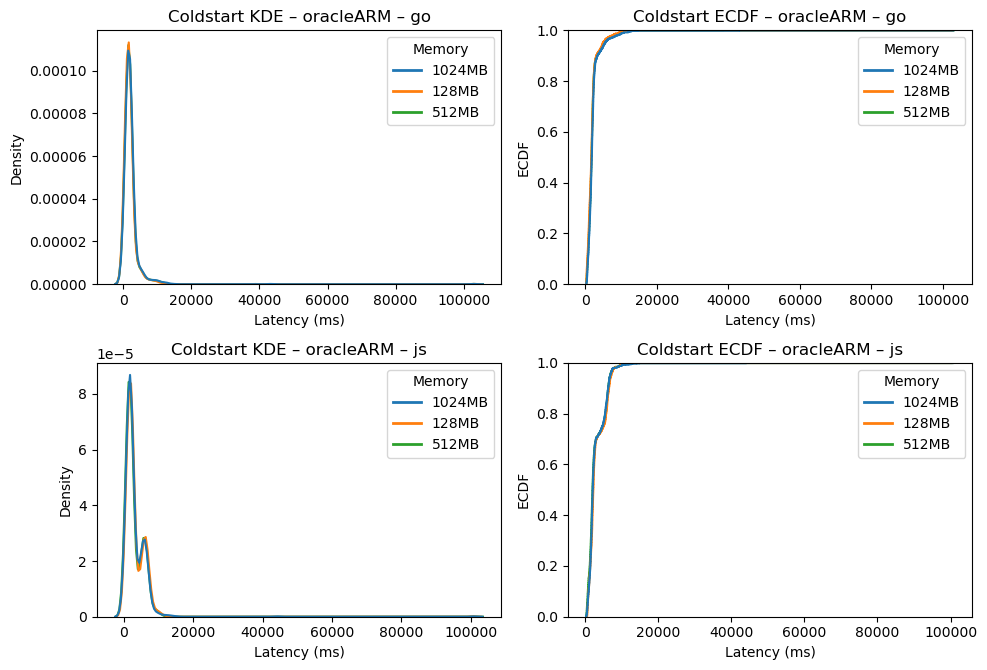

Coldstart KDE | deno | js | n=4763
Coldstart ECDF | deno | js | n=4763


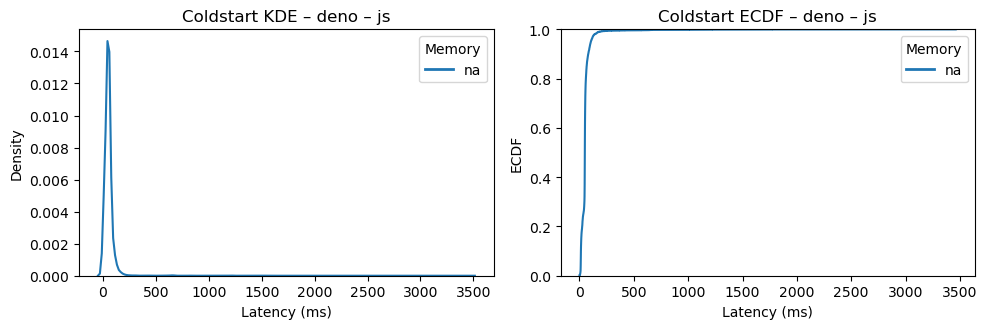

Coldstart KDE | cloudflare | js | n=4674
Coldstart ECDF | cloudflare | js | n=4674


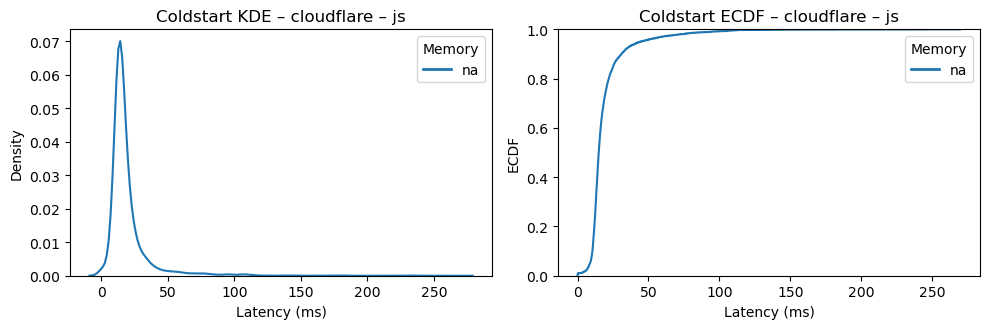

Coldstart KDE | flyio | go | n=14552
Coldstart ECDF | flyio | go | n=14552
Coldstart KDE | flyio | js | n=14554
Coldstart ECDF | flyio | js | n=14554


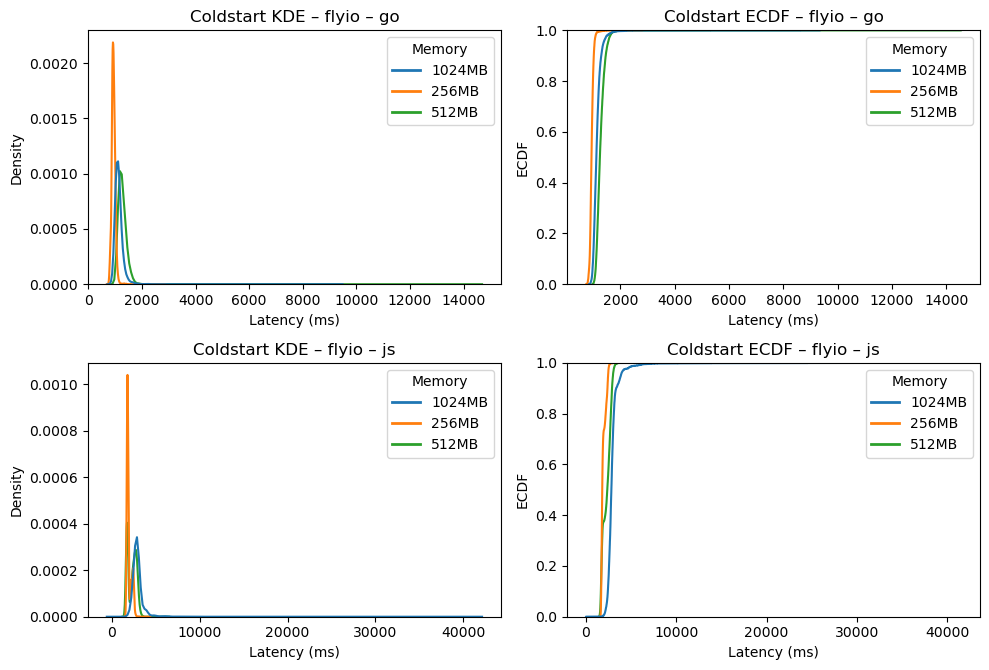

Coldstart KDE | fastly | go | n=5082
Coldstart ECDF | fastly | go | n=5082
Coldstart KDE | fastly | js | n=5088
Coldstart ECDF | fastly | js | n=5088


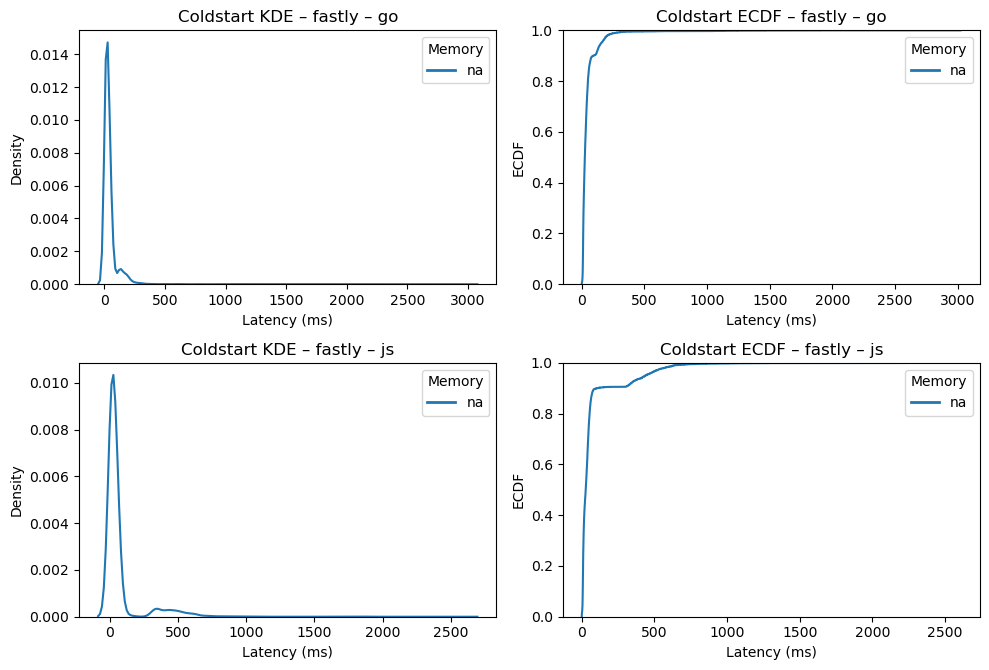

In [3]:
# KDE + ECDF plots of coldstart latency per provider, split by language and memory
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

for provider in providers:
    df_provider = pd.read_sql_query(
        """
        SELECT language, memory, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
        """,
        cnx,
        params=[provider],
    )
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider = df_provider.dropna(subset=["http_req_waiting", "language", "memory"])
    if df_provider.empty:
        continue

    df_provider["language"] = df_provider["language"].astype(str).str.lower()
    df_provider["memory"] = df_provider["memory"].astype(str)

    memory_order = sorted(df_provider["memory"].unique())
    palette = sns.color_palette("tab10", n_colors=len(memory_order))
    palette_map = {mem: color for mem, color in zip(memory_order, palette)}

    languages = sorted(df_provider["language"].unique())
    n_lang = len(languages)
    fig, axes = plt.subplots(nrows=n_lang, ncols=2, figsize=(10, 3.4 * n_lang), sharex=False)
    if n_lang == 1:
        axes = [axes]

    for row_axes, lang in zip(axes, languages):
        ax_kde, ax_ecdf = row_axes
        df_lang = df_provider[df_provider["language"] == lang]
        if df_lang.empty:
            ax_kde.set_visible(False)
            ax_ecdf.set_visible(False)
            continue
        print(f"Coldstart KDE | {provider} | {lang} | n={len(df_lang)}")
        sns.kdeplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            fill=False,
            bw_adjust=1.0,
            ax=ax_kde,
        )
        ax_kde.set_title(f"Coldstart KDE – {provider} – {lang}")
        ax_kde.set_xlabel("Latency (ms)")
        ax_kde.set_ylabel("Density")

        handles, labels = ax_kde.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_kde.legend(handles, labels, title="Memory", loc="best")

        print(f"Coldstart ECDF | {provider} | {lang} | n={len(df_lang)}")
        sns.ecdfplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            ax=ax_ecdf,
        )
        ax_ecdf.set_title(f"Coldstart ECDF – {provider} – {lang}")
        ax_ecdf.set_xlabel("Latency (ms)")
        ax_ecdf.set_ylabel("ECDF")

        handles, labels = ax_ecdf.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_ecdf.legend(handles, labels, title="Memory", loc="best")

    plt.tight_layout()
    plt.show()

Warmstart KDE (top 10%) | google | go | n=96
Warmstart ECDF (top 10%) | google | go | n=96
Warmstart KDE (top 10%) | google | js | n=96
Warmstart ECDF (top 10%) | google | js | n=96


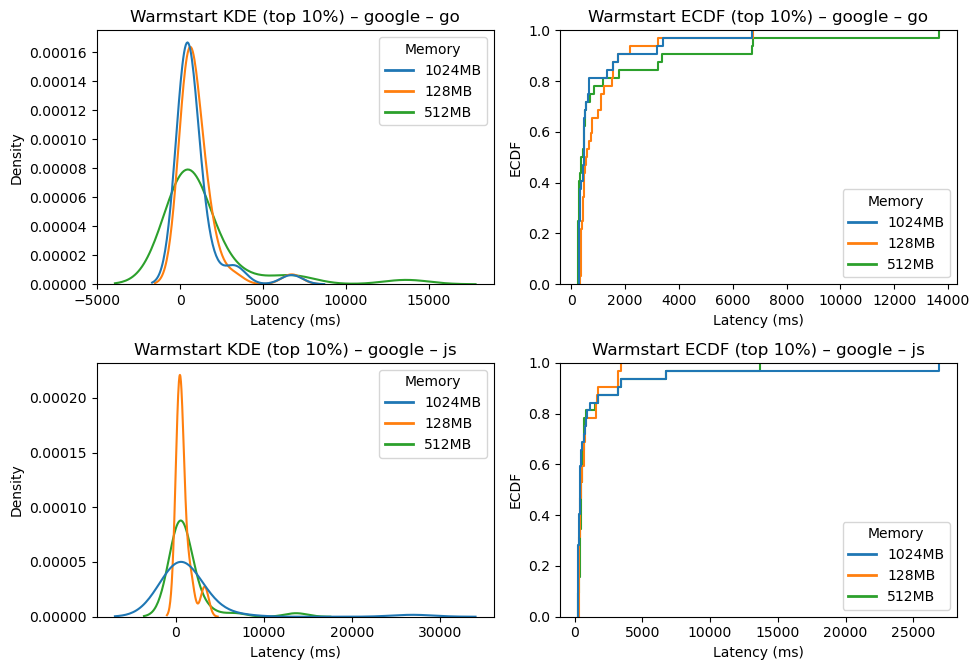

Warmstart KDE (top 10%) | awsX86 | go | n=67
Warmstart ECDF (top 10%) | awsX86 | go | n=67
Warmstart KDE (top 10%) | awsX86 | js | n=96
Warmstart ECDF (top 10%) | awsX86 | js | n=96


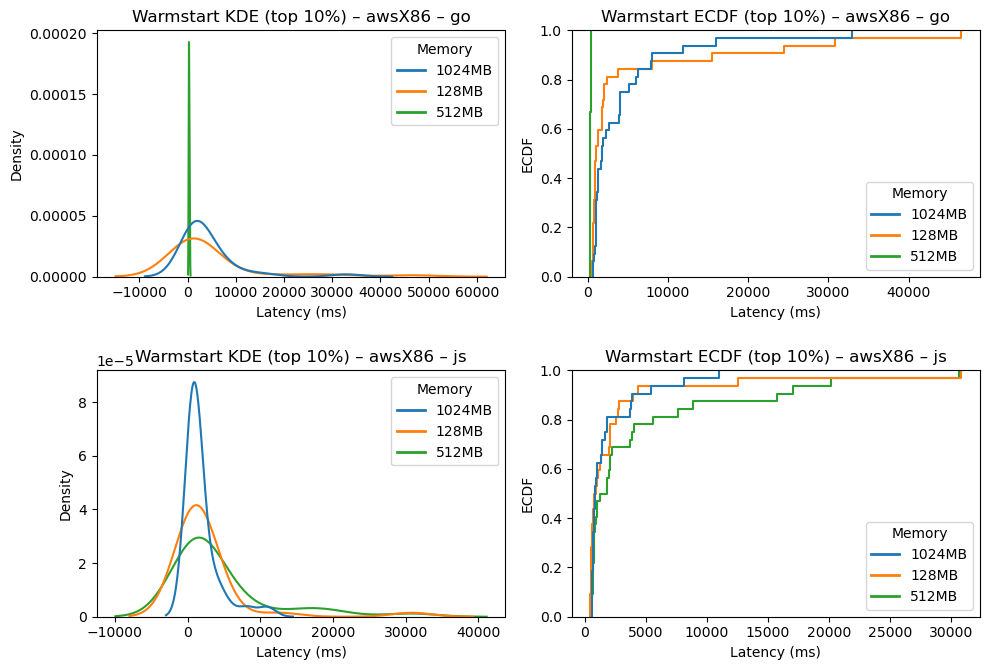

Warmstart KDE (top 10%) | awsARM | go | n=96
Warmstart ECDF (top 10%) | awsARM | go | n=96
Warmstart KDE (top 10%) | awsARM | js | n=96
Warmstart ECDF (top 10%) | awsARM | js | n=96


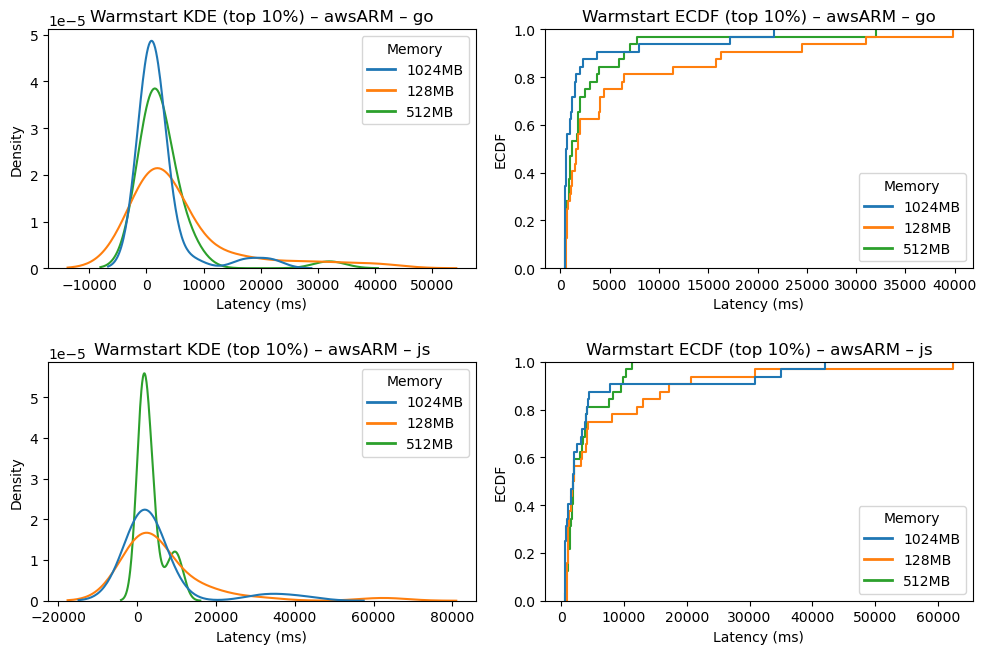

Warmstart KDE (top 10%) | oracleX86 | go | n=93
Warmstart ECDF (top 10%) | oracleX86 | go | n=93
Warmstart KDE (top 10%) | oracleX86 | js | n=93
Warmstart ECDF (top 10%) | oracleX86 | js | n=93


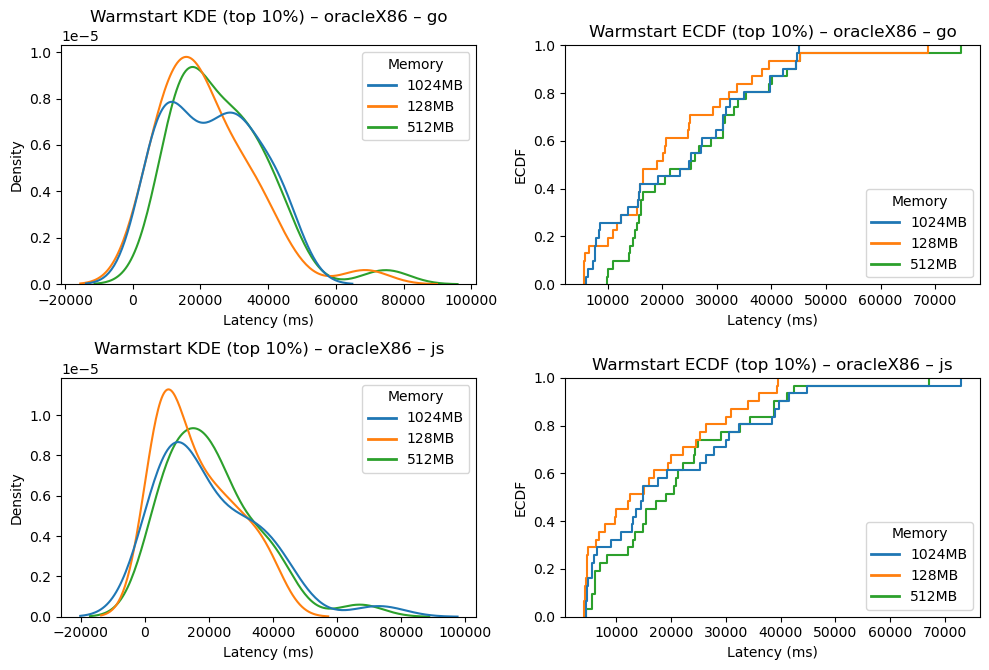

Warmstart KDE (top 10%) | oracleARM | go | n=96
Warmstart ECDF (top 10%) | oracleARM | go | n=96
Warmstart KDE (top 10%) | oracleARM | js | n=96
Warmstart ECDF (top 10%) | oracleARM | js | n=96


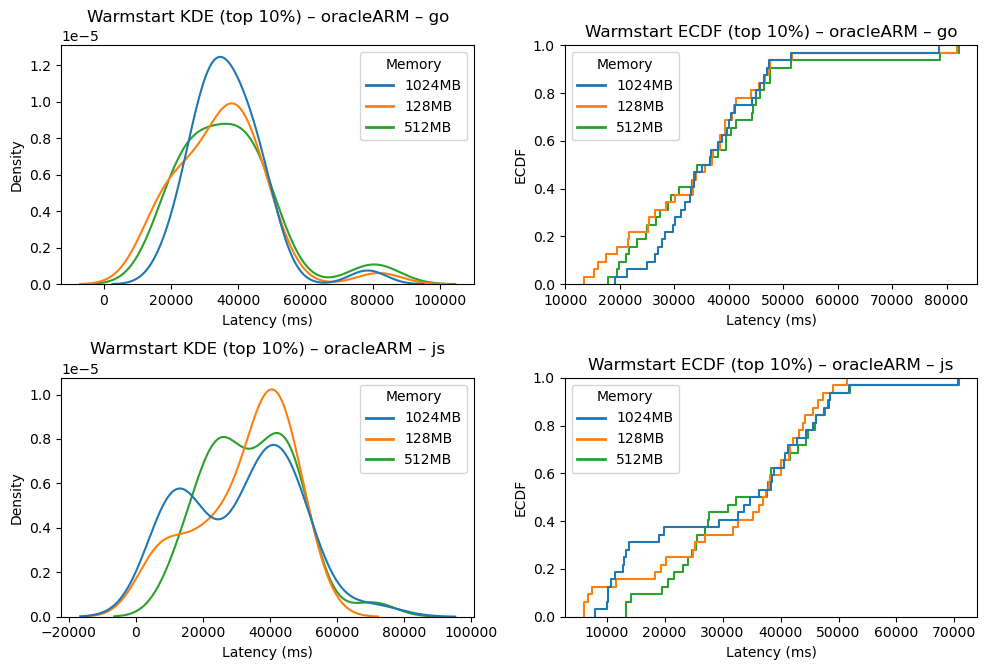

Warmstart KDE (top 10%) | deno | js | n=30
Warmstart ECDF (top 10%) | deno | js | n=30


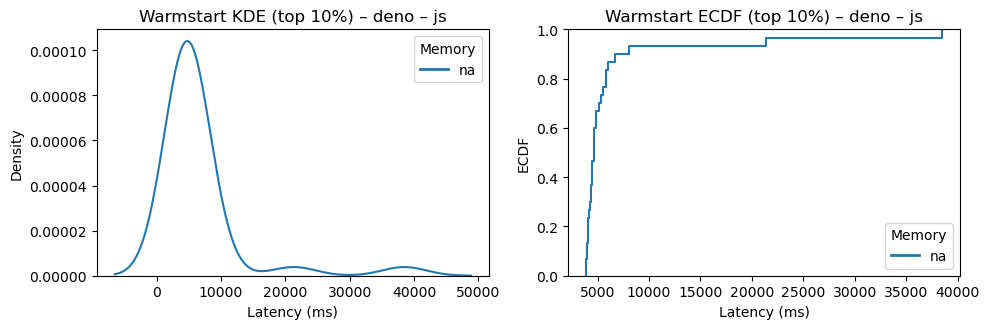

Warmstart KDE (top 10%) | cloudflare | js | n=28
Warmstart ECDF (top 10%) | cloudflare | js | n=28


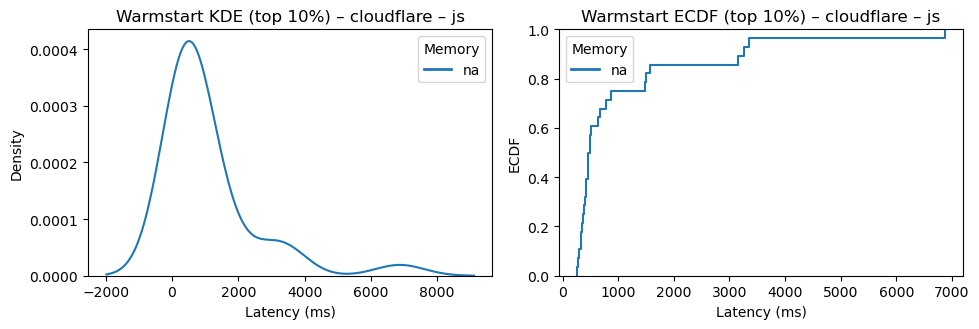

Warmstart KDE (top 10%) | flyio | go | n=96
Warmstart ECDF (top 10%) | flyio | go | n=96
Warmstart KDE (top 10%) | flyio | js | n=96
Warmstart ECDF (top 10%) | flyio | js | n=96


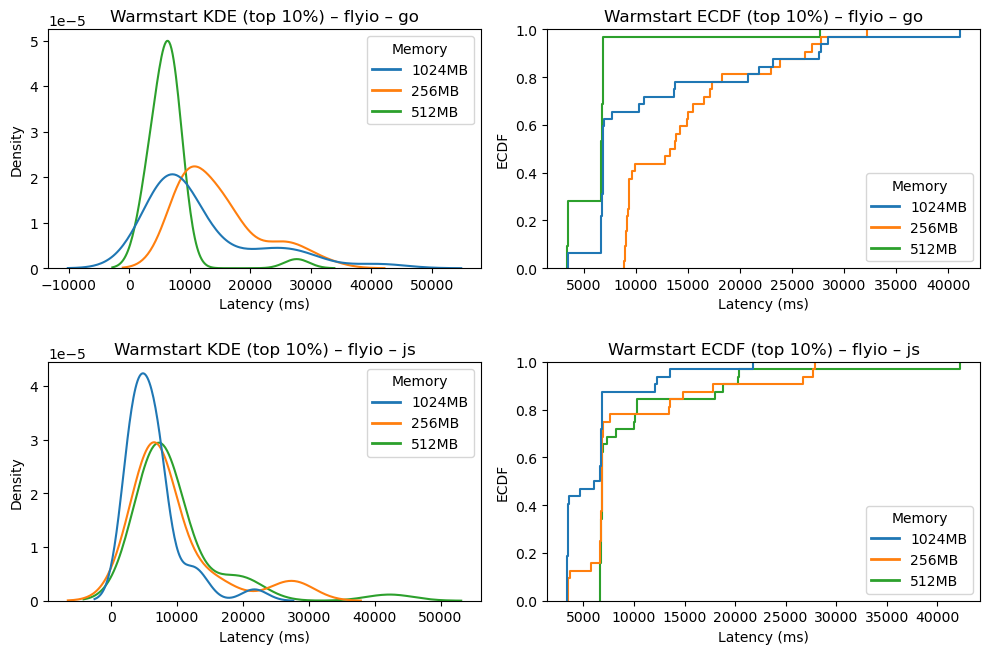

Warmstart KDE (top 10%) | fastly | go | n=33
Warmstart ECDF (top 10%) | fastly | go | n=33
Warmstart KDE (top 10%) | fastly | js | n=33
Warmstart ECDF (top 10%) | fastly | js | n=33


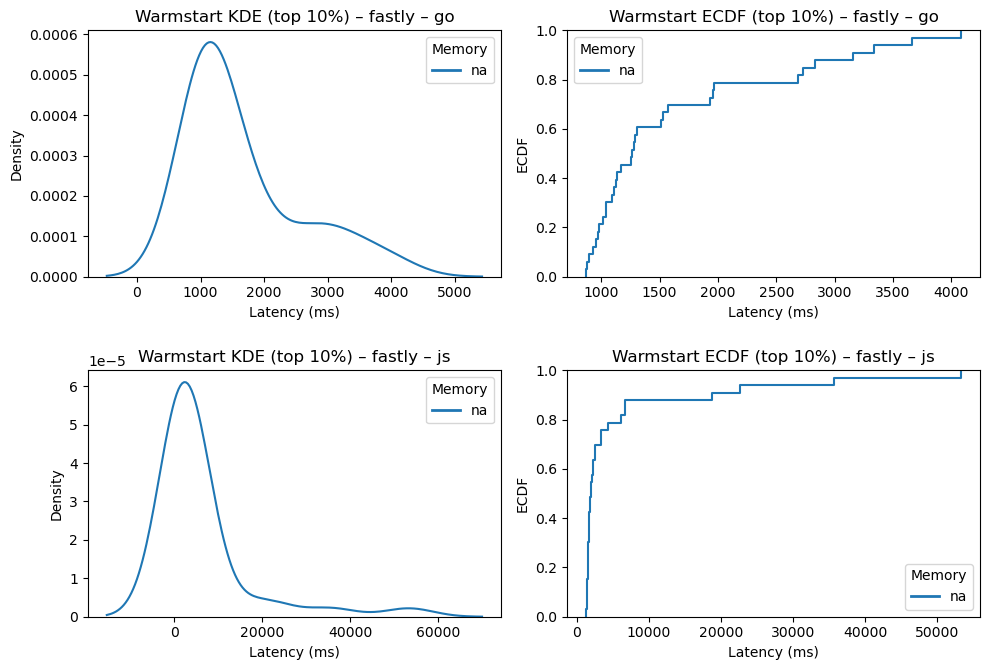

In [ ]:
# KDE + ECDF plots of warmstart latency (top 10%) per provider, split by language and memory
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

for provider in providers:
    if provider == "fastly":
        df_provider = pd.read_sql_query(
            """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
            """,
            cnx,
            params=[provider],
        )
    else:
        df_provider = pd.read_sql_query(
            """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
            """,
            cnx,
            params=[provider],
        )
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider = df_provider.dropna(subset=["http_req_waiting", "language", "memory"])
    if df_provider.empty:
        continue

    df_provider["language"] = df_provider["language"].astype(str).str.lower()
    df_provider["memory"] = df_provider["memory"].astype(str)

    p90 = df_provider.groupby(["language", "memory"])["http_req_waiting"].transform(lambda s: s.quantile(0.90))
    df_provider = df_provider[df_provider["http_req_waiting"] >= p90]
    if df_provider.empty:
        continue

    memory_order = sorted(df_provider["memory"].unique())
    palette = sns.color_palette("tab10", n_colors=len(memory_order))
    palette_map = {mem: color for mem, color in zip(memory_order, palette)}

    languages = sorted(df_provider["language"].unique())
    n_lang = len(languages)
    fig, axes = plt.subplots(nrows=n_lang, ncols=2, figsize=(10, 3.4 * n_lang), sharex=False)
    if n_lang == 1:
        axes = [axes]

    for row_axes, lang in zip(axes, languages):
        ax_kde, ax_ecdf = row_axes
        df_lang = df_provider[df_provider["language"] == lang]
        if df_lang.empty:
            ax_kde.set_visible(False)
            ax_ecdf.set_visible(False)
            continue
        print(f"Warmstart KDE (top 10%) | {provider} | {lang} | n={len(df_lang)}")
        sns.kdeplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            fill=False,
            bw_adjust=1.0,
            ax=ax_kde,
        )
        ax_kde.set_title(f"Warmstart KDE (top 10%) – {provider} – {lang}")
        ax_kde.set_xlabel("Latency (ms)")
        ax_kde.set_ylabel("Density")

        handles, labels = ax_kde.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_kde.legend(handles, labels, title="Memory", loc="best")

        print(f"Warmstart ECDF (top 10%) | {provider} | {lang} | n={len(df_lang)}")
        sns.ecdfplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            ax=ax_ecdf,
        )
        ax_ecdf.set_title(f"Warmstart ECDF (top 10%) – {provider} – {lang}")
        ax_ecdf.set_xlabel("Latency (ms)")
        ax_ecdf.set_ylabel("ECDF")

        handles, labels = ax_ecdf.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_ecdf.legend(handles, labels, title="Memory", loc="best")

    plt.tight_layout()
    plt.show()

Coldstart KDE (top 10%) | google | go | n=15
Coldstart ECDF (top 10%) | google | go | n=15
Coldstart KDE (top 10%) | google | js | n=12
Coldstart ECDF (top 10%) | google | js | n=12


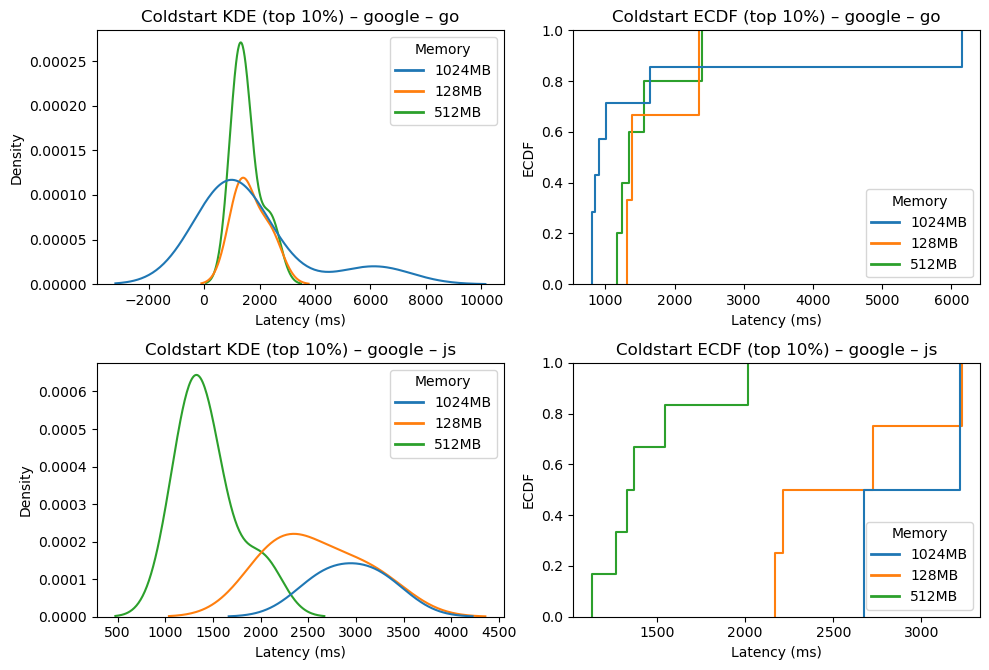

Coldstart KDE (top 10%) | awsX86 | go | n=129
Coldstart ECDF (top 10%) | awsX86 | go | n=129
Coldstart KDE (top 10%) | awsX86 | js | n=129
Coldstart ECDF (top 10%) | awsX86 | js | n=129


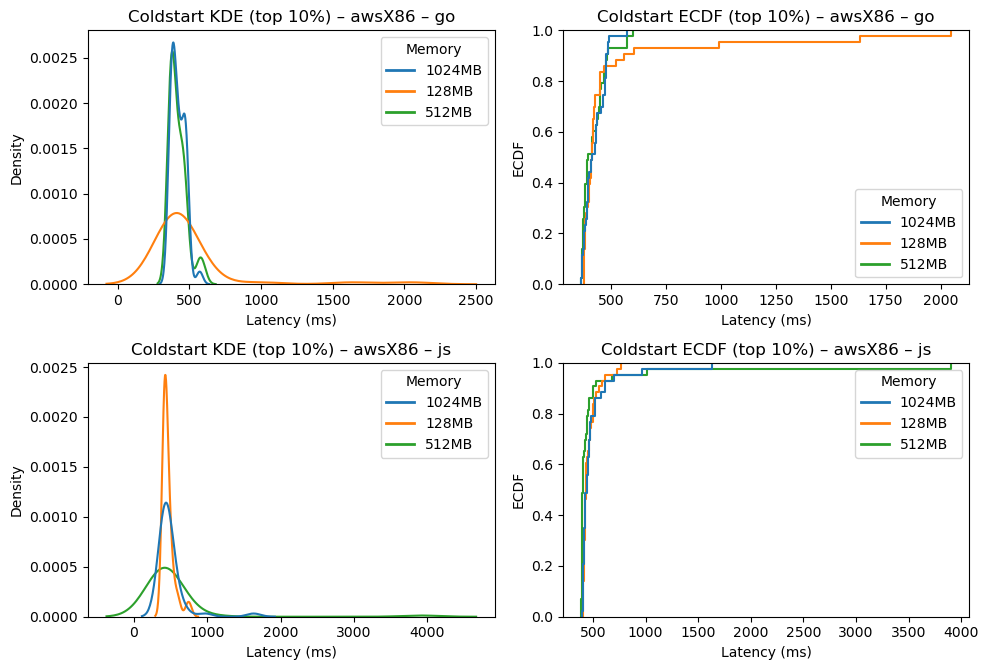

Coldstart KDE (top 10%) | awsARM | go | n=144
Coldstart ECDF (top 10%) | awsARM | go | n=144
Coldstart KDE (top 10%) | awsARM | js | n=143
Coldstart ECDF (top 10%) | awsARM | js | n=143


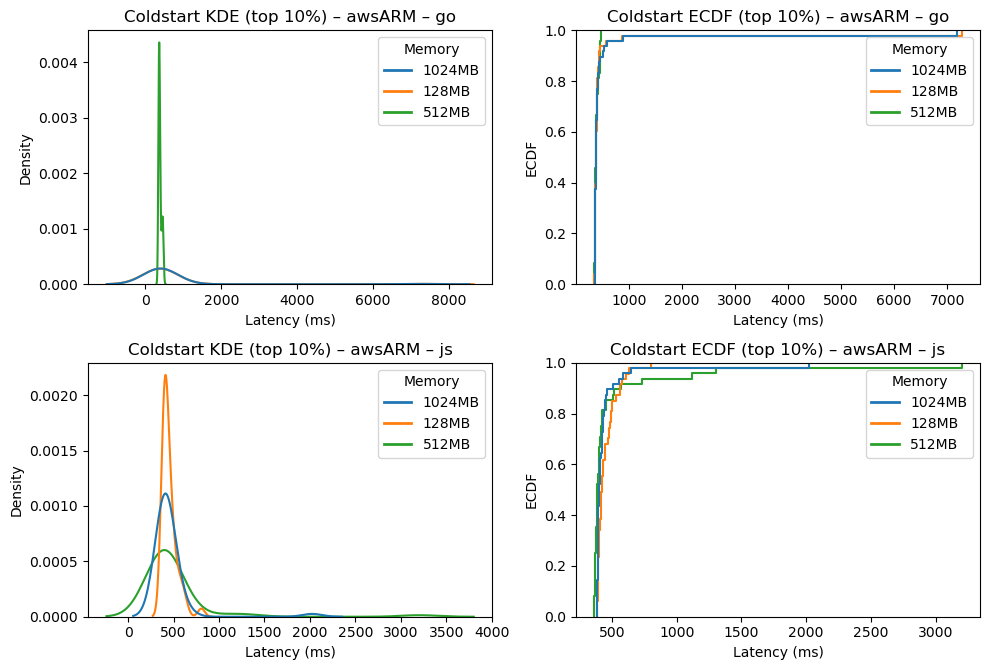

Coldstart KDE (top 10%) | oracleX86 | go | n=93
Coldstart ECDF (top 10%) | oracleX86 | go | n=93
Coldstart KDE (top 10%) | oracleX86 | js | n=92
Coldstart ECDF (top 10%) | oracleX86 | js | n=92


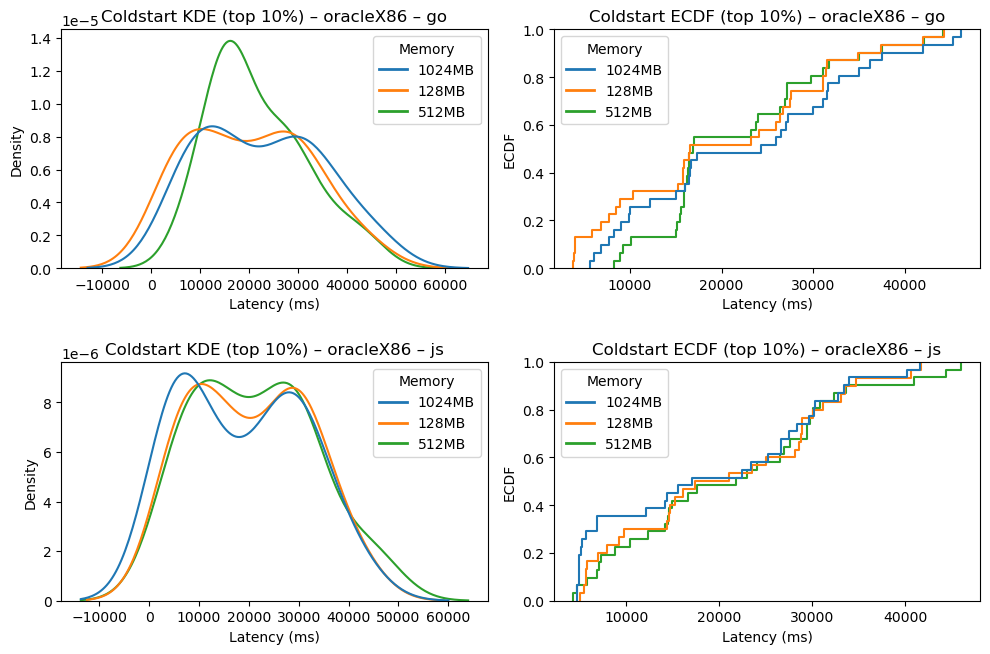

Coldstart KDE (top 10%) | oracleARM | go | n=39
Coldstart ECDF (top 10%) | oracleARM | go | n=39
Coldstart KDE (top 10%) | oracleARM | js | n=39
Coldstart ECDF (top 10%) | oracleARM | js | n=39


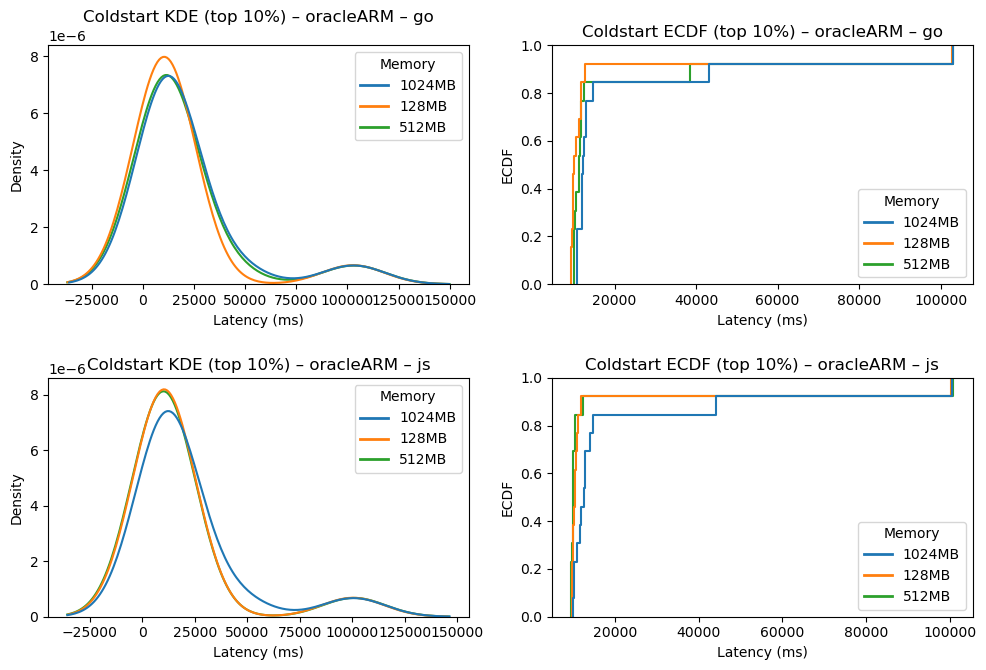

Coldstart KDE (top 10%) | deno | js | n=48
Coldstart ECDF (top 10%) | deno | js | n=48


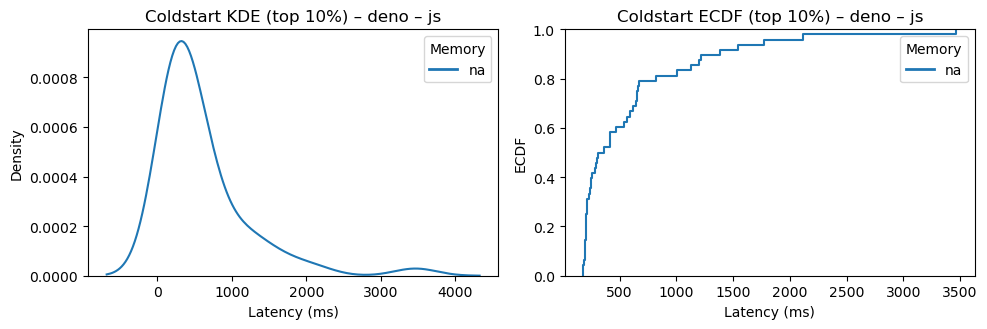

Coldstart KDE (top 10%) | cloudflare | js | n=47
Coldstart ECDF (top 10%) | cloudflare | js | n=47


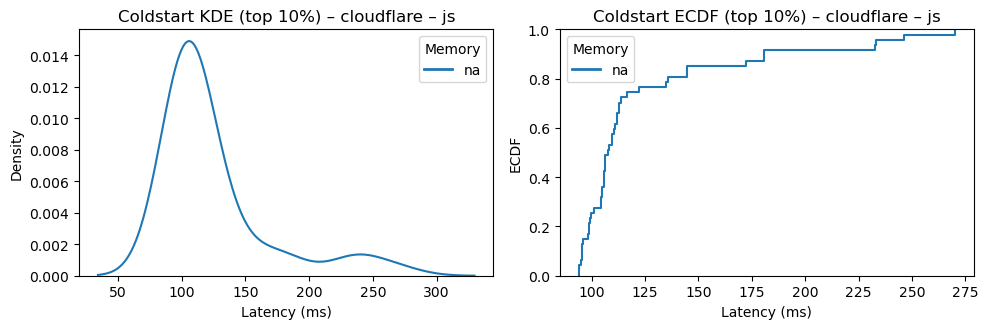

Coldstart KDE (top 10%) | flyio | go | n=148
Coldstart ECDF (top 10%) | flyio | go | n=148
Coldstart KDE (top 10%) | flyio | js | n=148
Coldstart ECDF (top 10%) | flyio | js | n=148


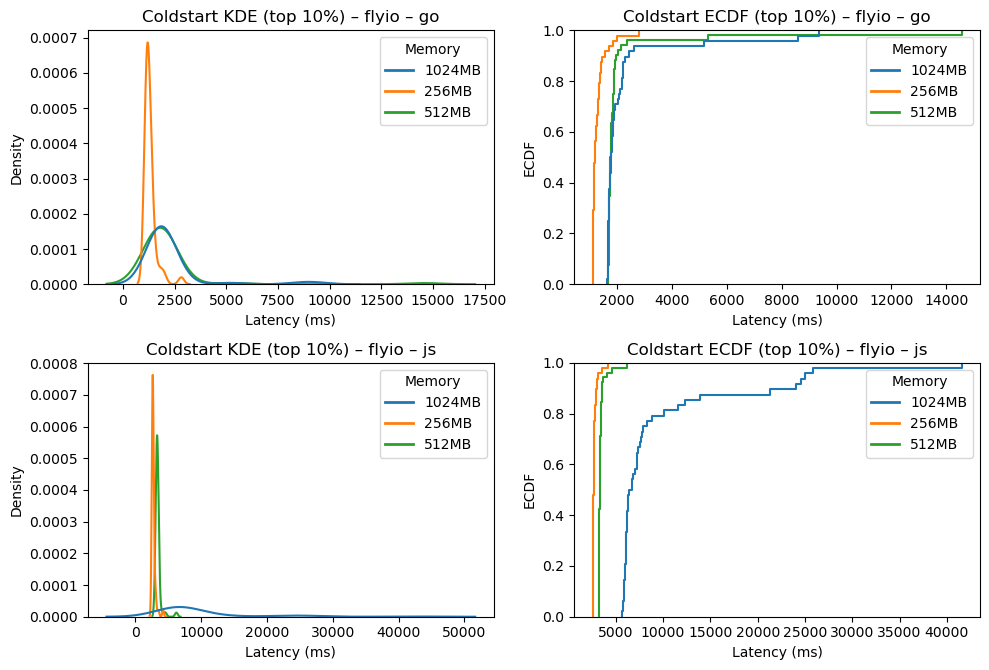

Coldstart KDE (top 10%) | fastly | go | n=51
Coldstart ECDF (top 10%) | fastly | go | n=51
Coldstart KDE (top 10%) | fastly | js | n=51
Coldstart ECDF (top 10%) | fastly | js | n=51


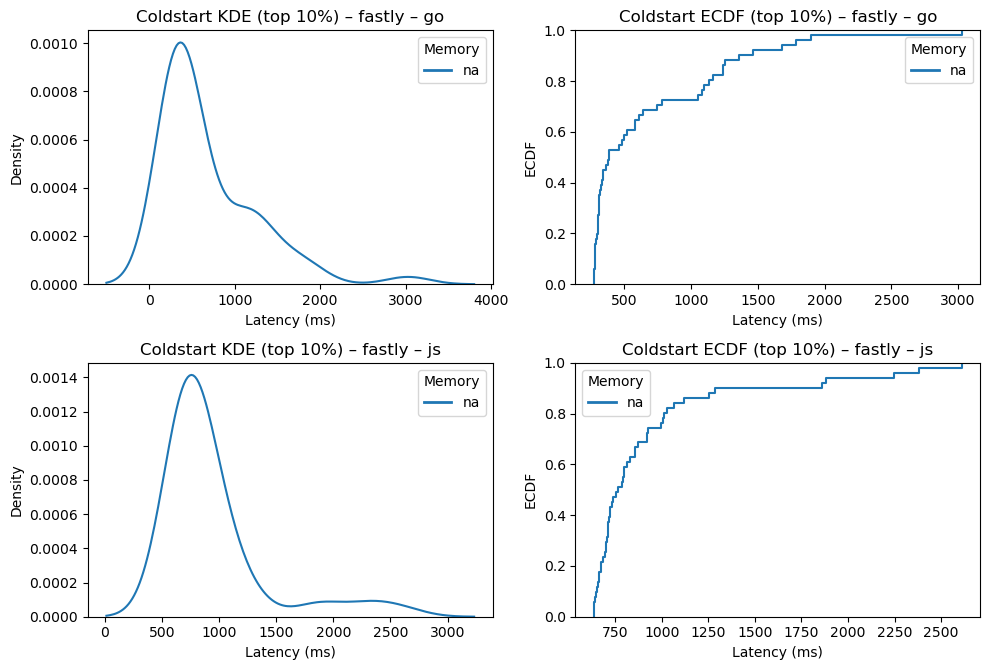

In [ ]:
# KDE + ECDF plots of coldstart latency (top 10%) per provider, split by language and memory
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

for provider in providers:
    df_provider = pd.read_sql_query(
        """
        SELECT language, memory, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
        """,
        cnx,
        params=[provider],
    )
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider = df_provider.dropna(subset=["http_req_waiting", "language", "memory"])
    if df_provider.empty:
        continue

    df_provider["language"] = df_provider["language"].astype(str).str.lower()
    df_provider["memory"] = df_provider["memory"].astype(str)

    p90 = df_provider.groupby(["language", "memory"])["http_req_waiting"].transform(lambda s: s.quantile(0.90))
    df_provider = df_provider[df_provider["http_req_waiting"] >= p90]
    if df_provider.empty:
        continue

    memory_order = sorted(df_provider["memory"].unique())
    palette = sns.color_palette("tab10", n_colors=len(memory_order))
    palette_map = {mem: color for mem, color in zip(memory_order, palette)}

    languages = sorted(df_provider["language"].unique())
    n_lang = len(languages)
    fig, axes = plt.subplots(nrows=n_lang, ncols=2, figsize=(10, 3.4 * n_lang), sharex=False)
    if n_lang == 1:
        axes = [axes]

    for row_axes, lang in zip(axes, languages):
        ax_kde, ax_ecdf = row_axes
        df_lang = df_provider[df_provider["language"] == lang]
        if df_lang.empty:
            ax_kde.set_visible(False)
            ax_ecdf.set_visible(False)
            continue
        print(f"Coldstart KDE (top 10%) | {provider} | {lang} | n={len(df_lang)}")
        sns.kdeplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            fill=False,
            bw_adjust=1.0,
            ax=ax_kde,
        )
        ax_kde.set_title(f"Coldstart KDE (top 10%) – {provider} – {lang}")
        ax_kde.set_xlabel("Latency (ms)")
        ax_kde.set_ylabel("Density")

        handles, labels = ax_kde.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_kde.legend(handles, labels, title="Memory", loc="best")

        print(f"Coldstart ECDF (top 10%) | {provider} | {lang} | n={len(df_lang)}")
        sns.ecdfplot(
            data=df_lang,
            x="http_req_waiting",
            hue="memory",
            hue_order=memory_order,
            palette=palette_map,
            ax=ax_ecdf,
        )
        ax_ecdf.set_title(f"Coldstart ECDF (top 10%) – {provider} – {lang}")
        ax_ecdf.set_xlabel("Latency (ms)")
        ax_ecdf.set_ylabel("ECDF")

        handles, labels = ax_ecdf.get_legend_handles_labels()
        if not labels:
            handles = [Line2D([0], [0], color=palette_map[mem], lw=2) for mem in memory_order]
            labels = memory_order
        ax_ecdf.legend(handles, labels, title="Memory", loc="best")

    plt.tight_layout()
    plt.show()

In [10]:
# Percentile table per configuration (provider + language + memory)
import pandas as pd
from IPython.display import display

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
percentiles = [0.99, 0.999, 0.9999, 0.99999, 0.999999, 1]
percentile_labels = ["p99", "p99.9", "p99.99", "p99.999", "p99.9999"]

def load_provider_frame(provider: str, experiment: str) -> pd.DataFrame:
    if experiment == "warmstart" and provider != "fastly":
        query = """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]
    elif experiment == "warmstart" and provider == "fastly":
        query = """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        """
        params = [provider]
    df = pd.read_sql_query(query, cnx, params=params)
    df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
    df = df.dropna(subset=["http_req_waiting", "language", "memory"])
    df["language"] = df["language"].astype(str).str.lower()
    df["memory"] = df["memory"].astype(str)
    df["provider"] = provider
    return df

def build_percentile_table(experiment: str) -> pd.DataFrame:
    frames = []
    for provider in providers:
        frames.append(load_provider_frame(provider, experiment))
    df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    if df.empty:
        return pd.DataFrame(columns=["provider", "language", "memory"] + percentile_labels)

    grouped = (
        df.groupby(["provider", "language", "memory"])["http_req_waiting"]
        .quantile(percentiles)
        .unstack(level=-1)
        .reset_index()
    )
    grouped = grouped.rename(columns={p: label for p, label in zip(percentiles, percentile_labels)})
    grouped = grouped.sort_values(["provider", "language", "memory"]).reset_index(drop=True)
    return grouped

table_warm = build_percentile_table("warmstart")
table_cold = build_percentile_table("coldstart")

print("Warmstart percentiles by configuration")
display(table_warm)
print("Coldstart percentiles by configuration")
display(table_cold)

Warmstart percentiles by configuration


,provider,language,memory,p99,p99.9,p99.99,p99.999,p99.9999,1.0
0,awsARM,go,1024MB,73.365676,117.717265,409.509252,3471.805271,20285.704505,21719.400005
1,awsARM,go,128MB,73.657144,124.017464,537.767206,16180.343798,37015.702255,39854.862577
2,awsARM,go,512MB,73.412543,116.756023,439.340279,6362.053369,24264.381322,32002.608667
3,awsARM,js,1024MB,74.636840,117.255884,516.126591,7076.263812,39807.797705,42073.080552
4,awsARM,js,128MB,90.643527,201.042610,855.795181,16927.016884,52358.629487,62453.638398
5,awsARM,js,512MB,75.704805,117.990891,621.550837,9217.806975,10974.962162,11265.852419
6,awsX86,go,1024MB,73.253342,117.660538,598.034718,8020.235946,27545.778472,32962.208942
7,awsX86,go,128MB,73.884200,119.036183,508.427728,14008.935097,41549.578652,46580.147065
8,awsX86,go,512MB,71.628123,106.483349,284.819163,397.167462,425.629155,428.791565
9,awsX86,js,1024MB,74.075799,116.481173,548.464849,3810.611422,10051.886712,10951.383031


Coldstart percentiles by configuration


,provider,language,memory,p99,p99.9,p99.99,p99.999,p99.9999,1.0
0,awsARM,go,1024MB,356.276743,475.103454,4210.941074,6886.450196,7154.001108,7183.728987
1,awsARM,go,128MB,349.938430,442.926363,4226.004877,6967.497608,7241.646881,7272.107911
2,awsARM,go,512MB,346.857653,453.419485,474.241392,479.953305,480.524496,480.587962
3,awsARM,js,1024MB,384.288026,476.013729,1376.670470,1959.827712,2018.143436,2024.622961
4,awsARM,js,128MB,384.312600,561.276911,724.924904,796.875221,804.070253,804.869701
5,awsARM,js,512MB,362.969701,530.611216,2304.613774,3110.562942,3191.157859,3200.112850
6,awsX86,go,1024MB,363.736386,476.024565,536.470131,569.011186,572.265292,572.626859
7,awsX86,go,128MB,374.672448,546.805892,1870.045844,2029.658013,2045.619230,2047.392699
8,awsX86,go,512MB,362.346491,477.006998,587.999956,599.126289,600.238922,600.362548
9,awsX86,js,1024MB,398.555720,601.536758,1350.645442,1603.242653,1628.502374,1631.309010


Compounded max for n=1: 3000 samples
Compounded max for n=5: 3000 samples
Compounded max for n=10: 3000 samples
Compounded max for n=50: 3000 samples


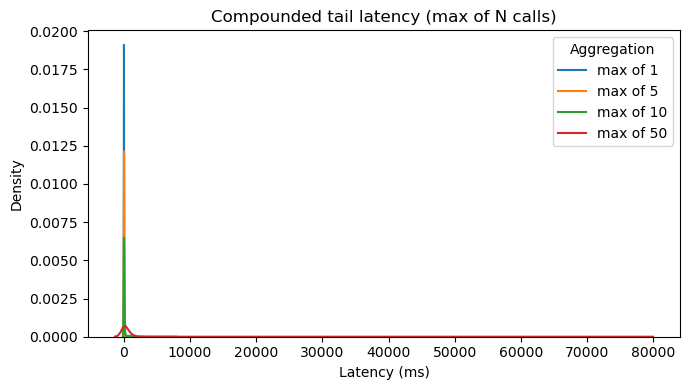

In [4]:
# Compounding tail latency KDE (max of N calls)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sample_query = """
    SELECT http_req_waiting
    FROM data
    WHERE experiment = 'warmstart'
      AND cold_starts = 0
"""
df_all = pd.read_sql_query(sample_query, cnx)
latencies = pd.to_numeric(df_all["http_req_waiting"], errors="coerce").dropna()

if latencies.empty:
    print("No warmstart latency data available for tail compounding plot.")
else:
    rng = np.random.default_rng(42)
    n_calls_list = [1, 5, 10, 50]
    n_samples = 3000
    samples = {}

    for n_calls in n_calls_list:
        draws = rng.choice(latencies.values, size=(n_samples, n_calls), replace=True)
        samples[n_calls] = draws.max(axis=1)
        print(f"Compounded max for n={n_calls}: {len(samples[n_calls])} samples")

    plt.figure(figsize=(7, 4))
    for n_calls in n_calls_list:
        sns.kdeplot(
            samples[n_calls],
            label=f"max of {n_calls}",
            bw_adjust=1.0,
        )
    plt.title("Compounded tail latency (max of N calls)")
    plt.xlabel("Latency (ms)")
    plt.ylabel("Density")
    plt.legend(title="Aggregation")
    plt.tight_layout()
    plt.show()

Provider google | max of 1: 3000 samples
Provider google | max of 5: 3000 samples
Provider google | max of 10: 3000 samples


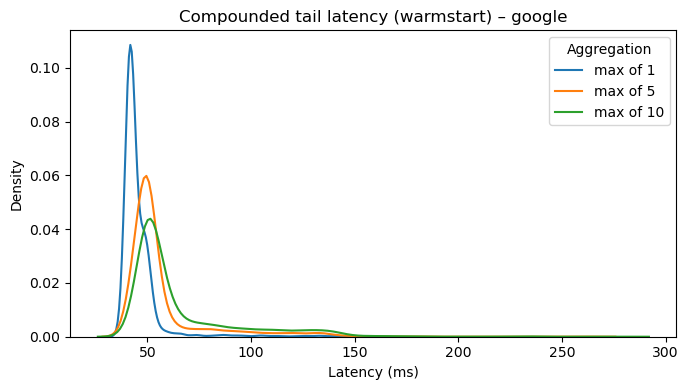

Provider awsX86 | max of 1: 3000 samples
Provider awsX86 | max of 5: 3000 samples
Provider awsX86 | max of 10: 3000 samples


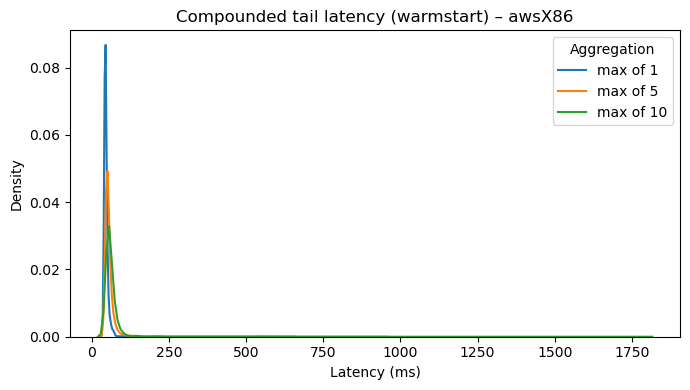

Provider awsARM | max of 1: 3000 samples
Provider awsARM | max of 5: 3000 samples
Provider awsARM | max of 10: 3000 samples


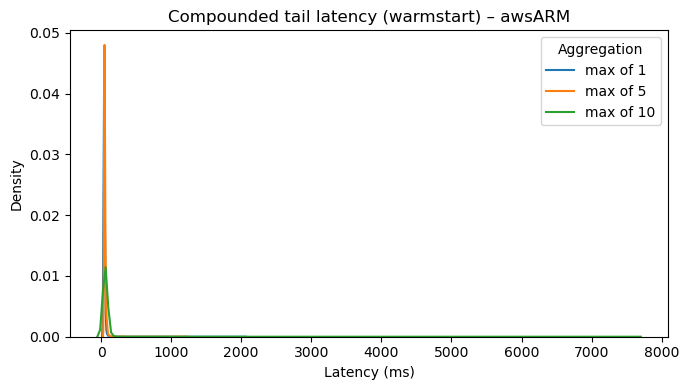

Provider oracleX86 | max of 1: 3000 samples
Provider oracleX86 | max of 5: 3000 samples
Provider oracleX86 | max of 10: 3000 samples


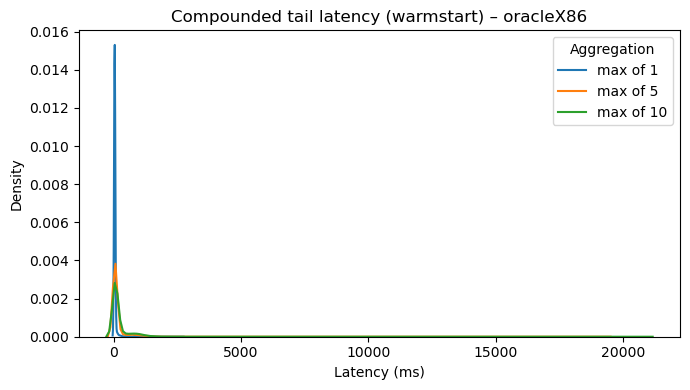

Provider oracleARM | max of 1: 3000 samples
Provider oracleARM | max of 5: 3000 samples
Provider oracleARM | max of 10: 3000 samples


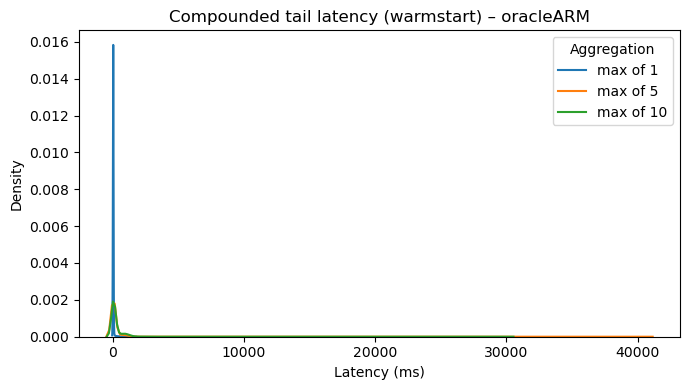

Provider deno | max of 1: 3000 samples
Provider deno | max of 5: 3000 samples
Provider deno | max of 10: 3000 samples


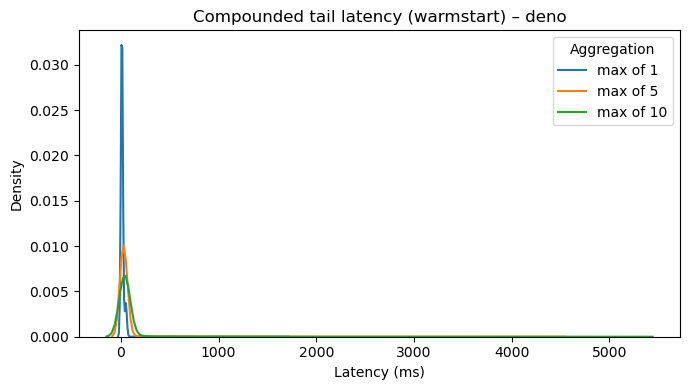

Provider cloudflare | max of 1: 3000 samples
Provider cloudflare | max of 5: 3000 samples
Provider cloudflare | max of 10: 3000 samples


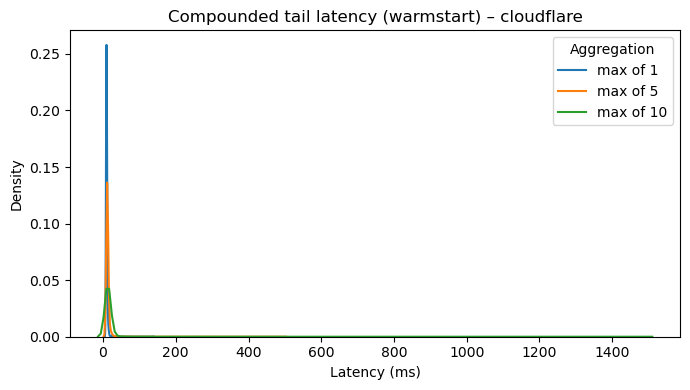

Provider flyio | max of 1: 3000 samples
Provider flyio | max of 5: 3000 samples
Provider flyio | max of 10: 3000 samples


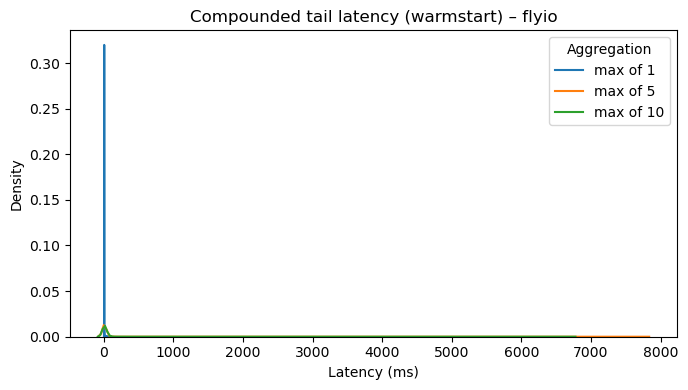

Provider fastly | max of 1: 3000 samples
Provider fastly | max of 5: 3000 samples
Provider fastly | max of 10: 3000 samples


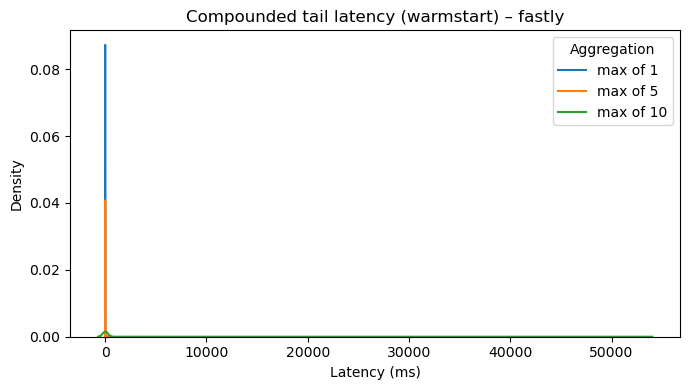

In [7]:
# Compounding tail latency KDE per provider (max of N calls)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
n_calls_list = [1, 5, 10]
n_samples = 3000
rng = np.random.default_rng(42)

for provider in providers:
    if provider == "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]

    df = pd.read_sql_query(query, cnx, params=params)
    latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()
    if latencies.empty:
        print(f"No warmstart latency data for provider {provider}.")
        continue

    plt.figure(figsize=(7, 4))
    for n_calls in n_calls_list:
        draws = rng.choice(latencies.values, size=(n_samples, n_calls), replace=True)
        max_samples = draws.max(axis=1)
        print(f"Provider {provider} | max of {n_calls}: {len(max_samples)} samples")
        sns.kdeplot(
            max_samples,
            label=f"max of {n_calls}",
            bw_adjust=1.0,
        )

    plt.title(f"Compounded tail latency (warmstart) – {provider}")
    plt.xlabel("Latency (ms)")
    plt.ylabel("Density")
    plt.legend(title="Aggregation")
    plt.tight_layout()
    plt.show()

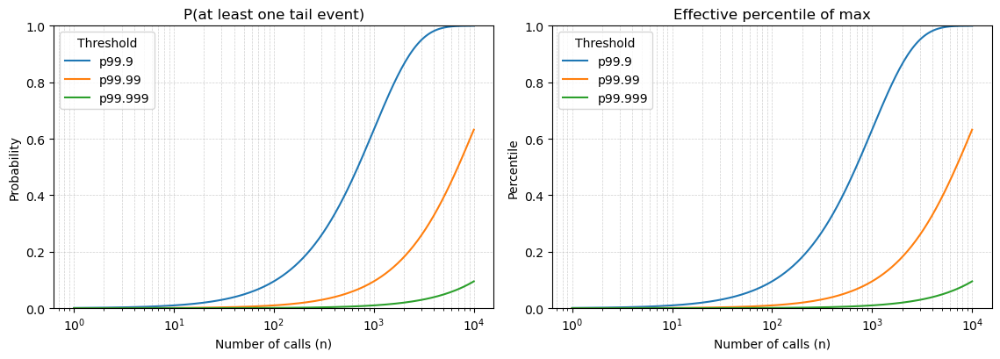

In [ ]:
percentiles = [0.999, 0.9999, 0.99999]
labels = ["p99.9", "p99.99", "p99.999"]

n = np.logspace(0, 4, 200)  # 1 to 10,000 calls
fig, (ax_prob, ax_eff) = plt.subplots(nrows=1, ncols=2, figsize=(11.5, 4.2))

for p, label in zip(percentiles, labels):
    q = 1.0 - p
    prob_tail = 1.0 - np.power((1.0 - q), n)
    ax_prob.semilogx(n, prob_tail, label=label)

    effective_percentile = 1.0 - np.power((1.0 - q), n)
    ax_eff.semilogx(n, effective_percentile, label=label)

ax_prob.set_title("P(at least one tail event)")
ax_prob.set_xlabel("Number of calls (n)")
ax_prob.set_ylabel("Probability")
ax_prob.set_ylim(0, 1)
ax_prob.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.6)
ax_prob.legend(title="Threshold")

ax_eff.set_title("Effective percentile of max")
ax_eff.set_xlabel("Number of calls (n)")
ax_eff.set_ylabel("Percentile")
ax_eff.set_ylim(0, 1)
ax_eff.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.6)
ax_eff.legend(title="Threshold")

plt.tight_layout()
plt.show()

In [31]:
# Tail-impact metrics per provider (max-of-N): inflation, expected max, tail mass, CCDF slope
import numpy as np
import pandas as pd
from IPython.display import display

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [10, 50, 100, 200, 500, 1000]  # N for max-of-N
n_samples = 4000
quantiles = [0.95, 0.99, 0.999]
thresholds_ms = [200, 500, 1000]  # tail-mass thresholds
tail_q_for_slope = 0.95
rng = np.random.default_rng(42)

def load_latencies(provider: str, experiment: str) -> np.ndarray:
    if experiment == "warmstart" and provider != "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]
    elif experiment == "warmstart" and provider == "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        """
        params = [provider]

    df = pd.read_sql_query(query, cnx, params=params)
    lat = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna().values
    return lat

def max_of_n_samples(latencies: np.ndarray, n: int, n_samples: int) -> np.ndarray:
    draws = rng.choice(latencies, size=(n_samples, n), replace=True)
    return draws.max(axis=1)

def ccdf_slope(samples: np.ndarray, tail_q: float = 0.95) -> float:
    if samples.size < 20:
        return np.nan
    s = np.sort(samples)
    cutoff = np.quantile(s, tail_q)
    tail = s[s >= cutoff]
    if tail.size < 10:
        return np.nan
    n = s.size
    start = n - tail.size
    idx_global = np.arange(start + 1, n + 1)
    ccdf = (n - idx_global + 0.5) / n
    mask = (ccdf > 0) & (tail > 0)
    if mask.sum() < 5:
        return np.nan
    slope = np.polyfit(np.log10(tail[mask]), np.log10(ccdf[mask]), 1)[0]
    return slope

rows = []

for provider in providers:
    latencies = load_latencies(provider, experiment)
    if latencies.size == 0:
        print(f"No latency data for provider {provider} ({experiment}).")
        continue

    per_call_mean = float(np.mean(latencies))
    per_call_q = {q: float(np.quantile(latencies, q)) for q in quantiles}
    per_call_tail = {t: float(np.mean(latencies > t)) for t in thresholds_ms}
    per_call_slope = ccdf_slope(latencies, tail_q_for_slope)

    for n in n_values:
        if n == 1:
            max_samples = latencies
        else:
            max_samples = max_of_n_samples(latencies, n, n_samples)

        max_mean = float(np.mean(max_samples))
        max_q = {q: float(np.quantile(max_samples, q)) for q in quantiles}
        max_tail = {t: float(np.mean(max_samples > t)) for t in thresholds_ms}
        max_slope = ccdf_slope(max_samples, tail_q_for_slope)

        row = {
            "provider": provider,
            "experiment": experiment,
            "n": n,
            "expected_max_ms": max_mean,
            "expected_max_ratio": max_mean / per_call_mean if per_call_mean > 0 else np.nan,
            "ccdf_slope_per_call": per_call_slope,
            "ccdf_slope_max_of_n": max_slope,
        }

        # Tail inflation factors
        for q in quantiles:
            row[f"p{int(q*1000)/10}_inflation"] = max_q[q] / per_call_q[q] if per_call_q[q] > 0 else np.nan

        # Tail mass (per-call vs max-of-N)
        for t in thresholds_ms:
            row[f"tail_mass_per_call_gt_{t}ms"] = per_call_tail[t]
            row[f"tail_mass_max_of_n_gt_{t}ms"] = max_tail[t]
            row[f"tail_mass_ratio_gt_{t}ms"] = (max_tail[t] / per_call_tail[t]) if per_call_tail[t] > 0 else np.nan

        rows.append(row)

metrics_df = pd.DataFrame(rows)
display(metrics_df)

,provider,experiment,n,expected_max_ms,expected_max_ratio,ccdf_slope_per_call,ccdf_slope_max_of_n,p95.0_inflation,p99.0_inflation,p99.9_inflation,tail_mass_per_call_gt_200ms,tail_mass_max_of_n_gt_200ms,tail_mass_ratio_gt_200ms,tail_mass_per_call_gt_500ms,tail_mass_max_of_n_gt_500ms,tail_mass_ratio_gt_500ms,tail_mass_per_call_gt_1000ms,tail_mass_max_of_n_gt_1000ms,tail_mass_ratio_gt_1000ms
0,google,warmstart,10,64.670599,1.408804,-2.900019,-6.914443,2.292631,1.348004,1.541768,0.000376,0.00225,5.989681,0.000042,0.00000,0.000000,0.000022,0.00000,0.000000
1,google,warmstart,50,102.697493,2.237194,-2.900019,-2.241036,2.723371,2.061493,3.657697,0.000376,0.01800,47.917448,0.000042,0.00125,29.619753,0.000022,0.00075,33.477209
2,google,warmstart,100,131.061857,2.855092,-2.900019,-1.527408,3.251565,2.455524,10.232625,0.000376,0.03575,95.169376,0.000042,0.00400,94.783210,0.000022,0.00200,89.272558
3,google,warmstart,200,156.899127,3.417939,-2.900019,-1.370960,3.972823,3.363839,21.283540,0.000376,0.07450,198.324993,0.000042,0.00525,124.402963,0.000022,0.00250,111.590698
4,google,warmstart,500,233.474944,5.086090,-2.900019,-0.958963,5.017302,14.049073,90.312481,0.000376,0.17925,477.177920,0.000042,0.02350,556.851358,0.000022,0.01275,569.112558
5,google,warmstart,1000,276.938949,6.032923,-2.900019,-1.056458,8.646969,28.779186,90.224353,0.000376,0.30525,812.600055,0.000042,0.04575,1084.082963,0.000022,0.02400,1071.270698
6,awsX86,warmstart,10,61.877085,1.336106,-3.560878,-2.195171,1.536809,1.769486,4.575515,0.000418,0.00525,12.571607,0.000109,0.00125,11.431808,0.000054,0.00025,4.598705
7,awsX86,warmstart,50,99.749332,2.153879,-3.560878,-1.141747,2.426354,3.984974,38.812621,0.000418,0.02200,52.681018,0.000109,0.00600,54.872678,0.000054,0.00300,55.184455
8,awsX86,warmstart,100,138.484725,2.990289,-3.560878,-0.996975,3.208784,8.124629,56.920019,0.000418,0.04575,109.552571,0.000109,0.01300,118.890802,0.000054,0.00750,137.961136
9,awsX86,warmstart,200,187.225665,4.042747,-3.560878,-0.909010,4.874020,15.521888,110.643760,0.000418,0.08300,198.751112,0.000109,0.02050,187.481650,0.000054,0.01125,206.941705


Provider google | max of 10: 4000 samples
Provider google | max of 50: 4000 samples
Provider google | max of 100: 4000 samples
Provider google | max of 200: 4000 samples
Provider google | max of 500: 4000 samples


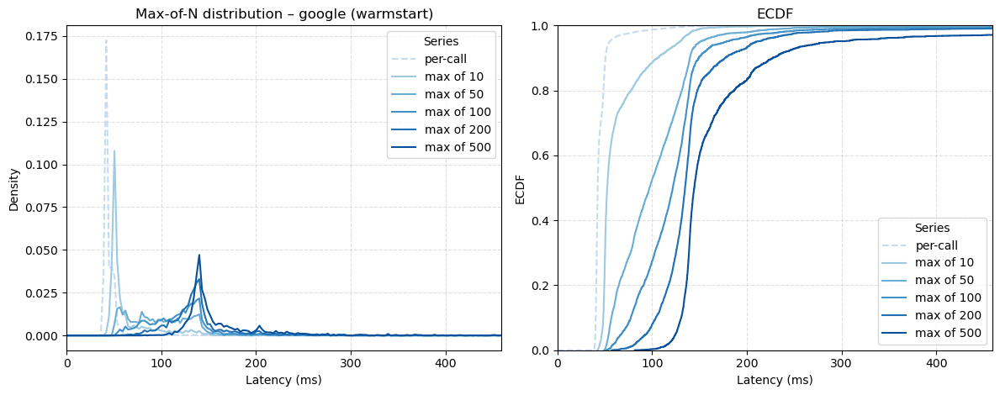

Provider awsX86 | max of 10: 4000 samples
Provider awsX86 | max of 50: 4000 samples
Provider awsX86 | max of 100: 4000 samples
Provider awsX86 | max of 200: 4000 samples
Provider awsX86 | max of 500: 4000 samples


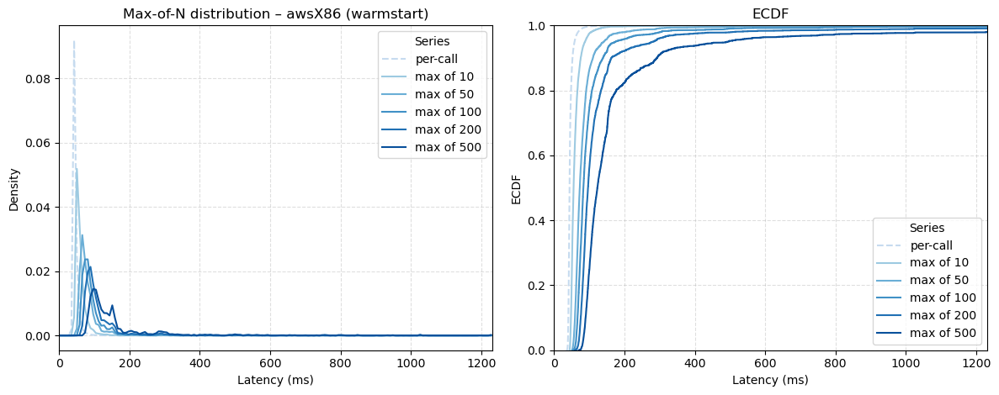

Provider awsARM | max of 10: 4000 samples
Provider awsARM | max of 50: 4000 samples
Provider awsARM | max of 100: 4000 samples
Provider awsARM | max of 200: 4000 samples
Provider awsARM | max of 500: 4000 samples


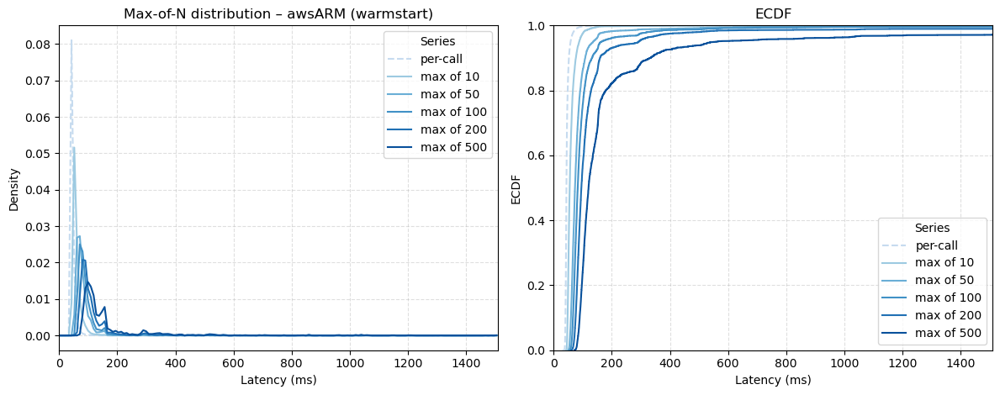

Provider oracleX86 | max of 10: 4000 samples
Provider oracleX86 | max of 50: 4000 samples
Provider oracleX86 | max of 100: 4000 samples
Provider oracleX86 | max of 200: 4000 samples
Provider oracleX86 | max of 500: 4000 samples


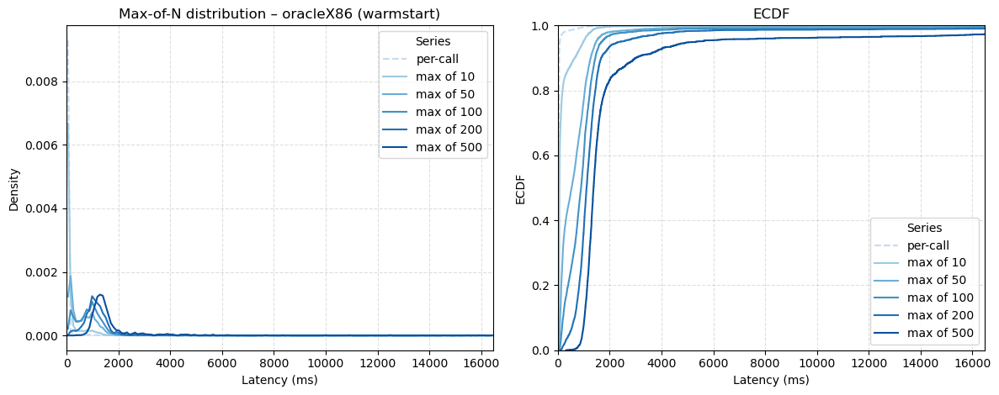

Provider oracleARM | max of 10: 4000 samples
Provider oracleARM | max of 50: 4000 samples
Provider oracleARM | max of 100: 4000 samples
Provider oracleARM | max of 200: 4000 samples
Provider oracleARM | max of 500: 4000 samples


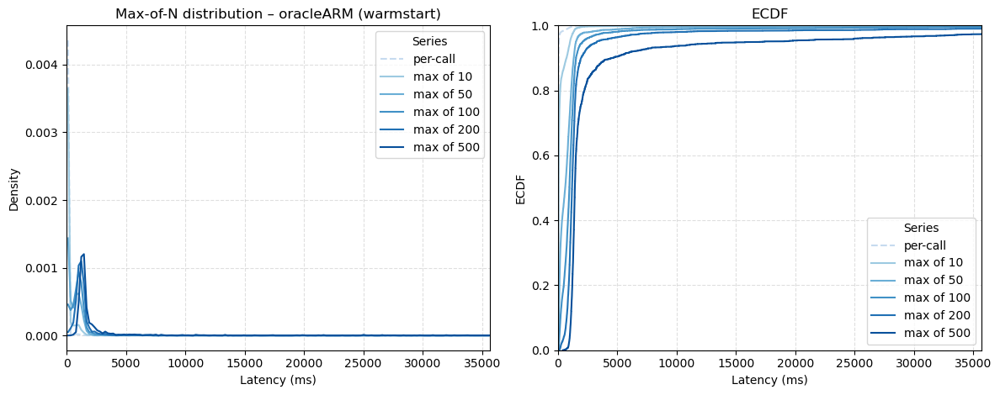

Provider deno | max of 10: 4000 samples
Provider deno | max of 50: 4000 samples
Provider deno | max of 100: 4000 samples
Provider deno | max of 200: 4000 samples
Provider deno | max of 500: 4000 samples


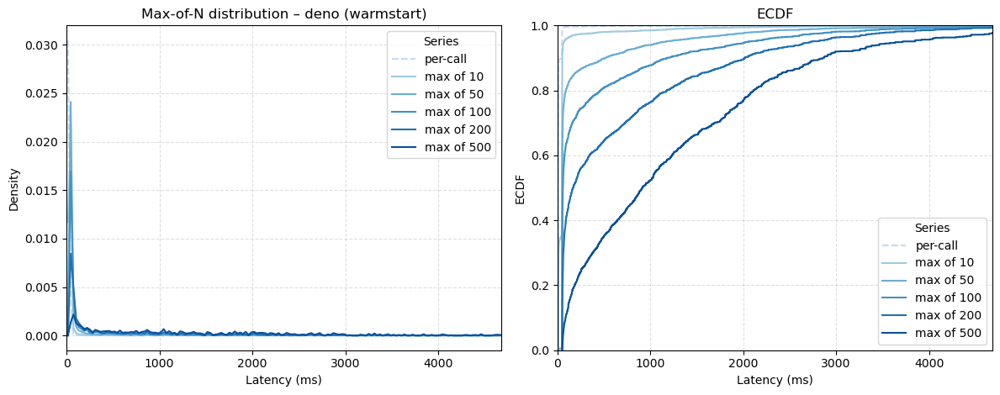

Provider cloudflare | max of 10: 4000 samples
Provider cloudflare | max of 50: 4000 samples
Provider cloudflare | max of 100: 4000 samples
Provider cloudflare | max of 200: 4000 samples
Provider cloudflare | max of 500: 4000 samples


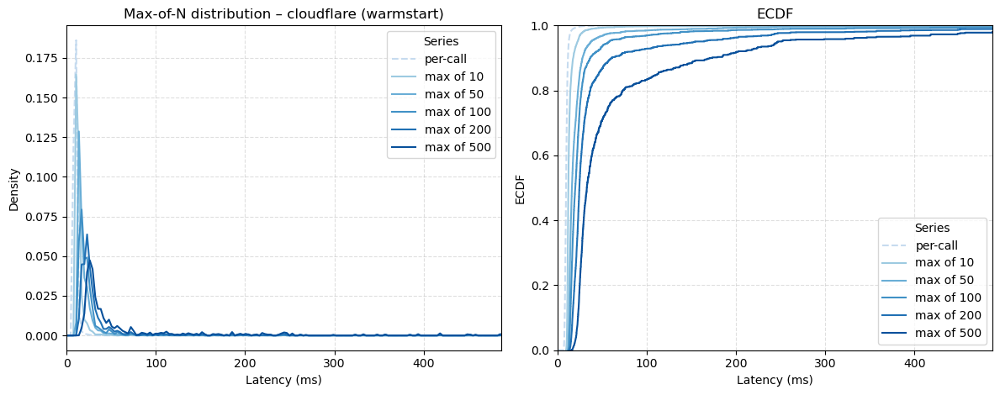

Provider flyio | max of 10: 4000 samples
Provider flyio | max of 50: 4000 samples
Provider flyio | max of 100: 4000 samples
Provider flyio | max of 200: 4000 samples
Provider flyio | max of 500: 4000 samples


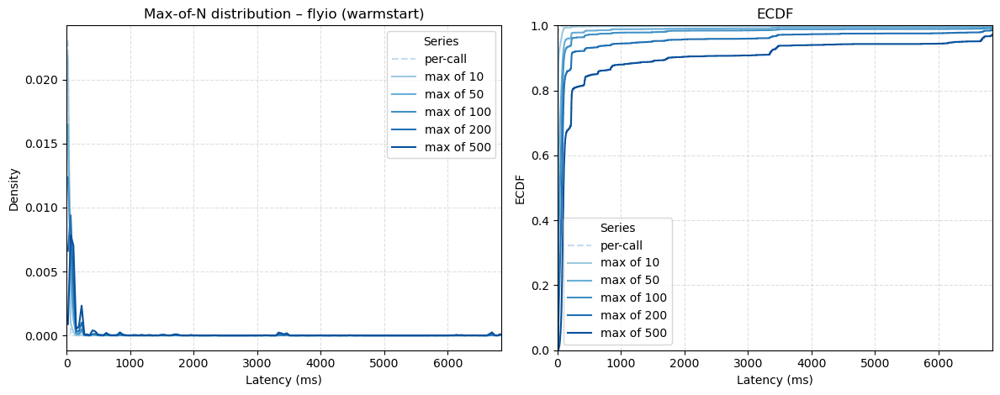

Provider fastly | max of 10: 4000 samples
Provider fastly | max of 50: 4000 samples
Provider fastly | max of 100: 4000 samples
Provider fastly | max of 200: 4000 samples
Provider fastly | max of 500: 4000 samples


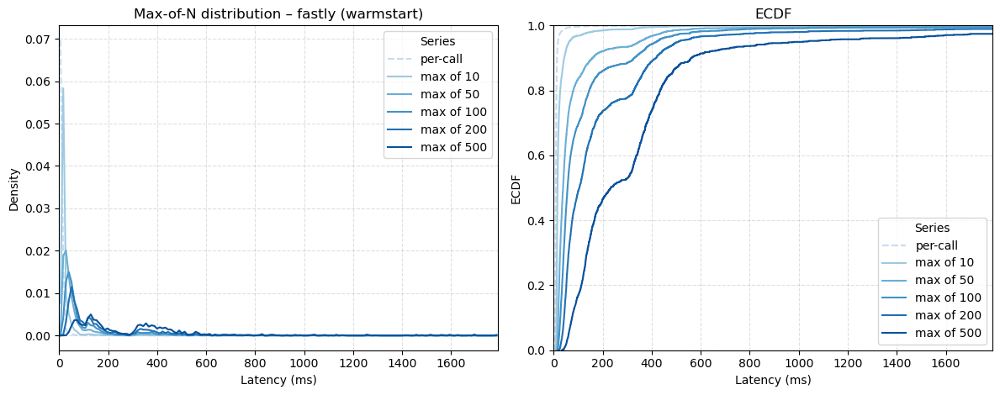

In [33]:
# Actual-data overlay: max-of-N distribution curves on one plot (per provider)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [10, 50, 100, 200, 500, 1000]
samples_per_n = 4000
rng = np.random.default_rng(42)

def density_line(samples: np.ndarray, bins: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    hist, edges = np.histogram(samples, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, hist

for provider in providers:
    if experiment == "warmstart" and provider != "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]
    elif experiment == "warmstart" and provider == "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        """
        params = [provider]

    df = pd.read_sql_query(query, cnx, params=params)
    latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()

    if latencies.empty:
        print(f"No latency data for provider {provider} ({experiment}).")
        continue

    max_n = max(n_values)
    max_samples_for_xlim = rng.choice(latencies.values, size=(samples_per_n, max_n), replace=True).max(axis=1)
    x_min = 0
    x_max_q = 95
    x_max = np.percentile(max_samples_for_xlim, x_max_q)
    bins = np.linspace(x_min, x_max, 160)

    ramp = sns.color_palette("Blues", n_colors=len(n_values) + 1)
    base_color = ramp[1]
    line_colors = ramp[2:]

    fig, (ax_dist, ax_ecdf) = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
    x_base, y_base = density_line(latencies.values, bins)
    sns.lineplot(x=x_base, y=y_base, color=base_color, linestyle="--", label="per-call", ax=ax_dist)
    sns.ecdfplot(latencies.values, color=base_color, linestyle="--", label="per-call", ax=ax_ecdf)

    for n, color in zip(n_values, line_colors):
        draws = rng.choice(latencies.values, size=(samples_per_n, n), replace=True)
        max_samples = draws.max(axis=1)
        print(f"Provider {provider} | max of {n}: {len(max_samples)} samples")
        x_line, y_line = density_line(max_samples, bins)
        sns.lineplot(x=x_line, y=y_line, color=color, label=f"max of {n}", ax=ax_dist)
        sns.ecdfplot(max_samples, color=color, label=f"max of {n}", ax=ax_ecdf)

    ax_dist.set_title(f"Max-of-N distribution – {provider} ({experiment})")
    ax_dist.set_xlabel("Latency (ms)")
    ax_dist.set_ylabel("Density")
    ax_dist.grid(True, linestyle="--", alpha=0.4)
    ax_dist.set_xlim(x_min, x_max)
    ax_dist.legend(title="Series")

    ax_ecdf.set_title("ECDF")
    ax_ecdf.set_xlabel("Latency (ms)")
    ax_ecdf.set_ylabel("ECDF")
    ax_ecdf.grid(True, linestyle="--", alpha=0.4)
    ax_ecdf.set_xlim(x_min, x_max)
    ax_ecdf.legend(title="Series")

    fig.tight_layout()
    plt.show()

Provider google | sum of 10: 4000 samples
Provider google | sum of 50: 4000 samples
Provider google | sum of 100: 4000 samples
Provider google | sum of 200: 4000 samples
Provider google | sum of 500: 4000 samples


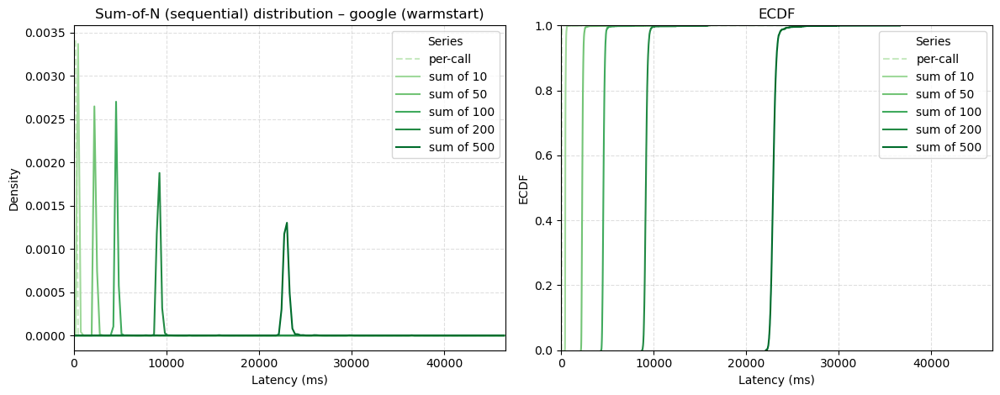

Provider awsX86 | sum of 10: 4000 samples
Provider awsX86 | sum of 50: 4000 samples
Provider awsX86 | sum of 100: 4000 samples
Provider awsX86 | sum of 200: 4000 samples
Provider awsX86 | sum of 500: 4000 samples


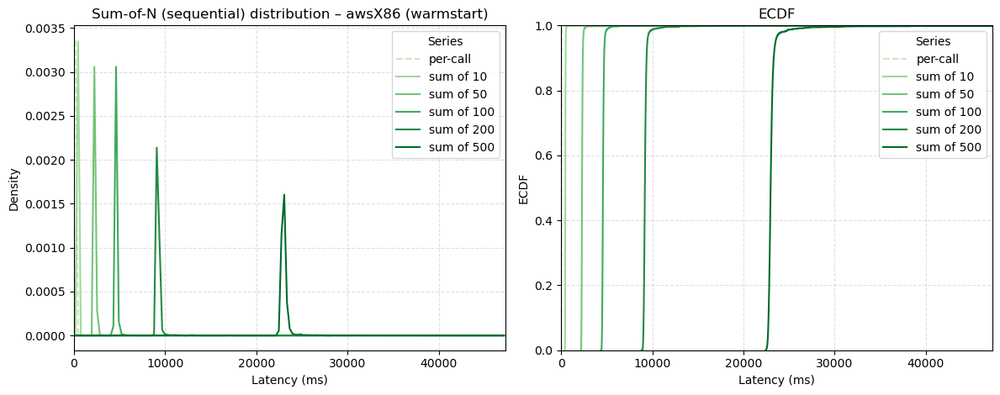

Provider awsARM | sum of 10: 4000 samples
Provider awsARM | sum of 50: 4000 samples
Provider awsARM | sum of 100: 4000 samples
Provider awsARM | sum of 200: 4000 samples
Provider awsARM | sum of 500: 4000 samples


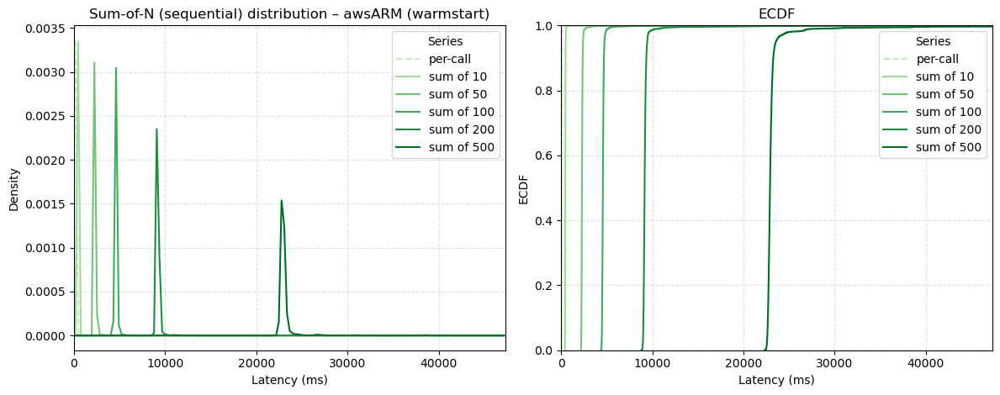

Provider oracleX86 | sum of 10: 4000 samples
Provider oracleX86 | sum of 50: 4000 samples
Provider oracleX86 | sum of 100: 4000 samples
Provider oracleX86 | sum of 200: 4000 samples
Provider oracleX86 | sum of 500: 4000 samples


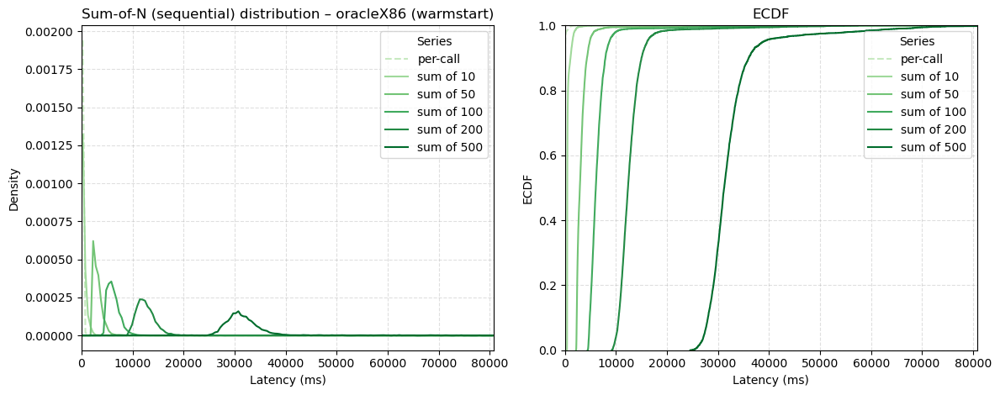

Provider oracleARM | sum of 10: 4000 samples
Provider oracleARM | sum of 50: 4000 samples
Provider oracleARM | sum of 100: 4000 samples
Provider oracleARM | sum of 200: 4000 samples
Provider oracleARM | sum of 500: 4000 samples


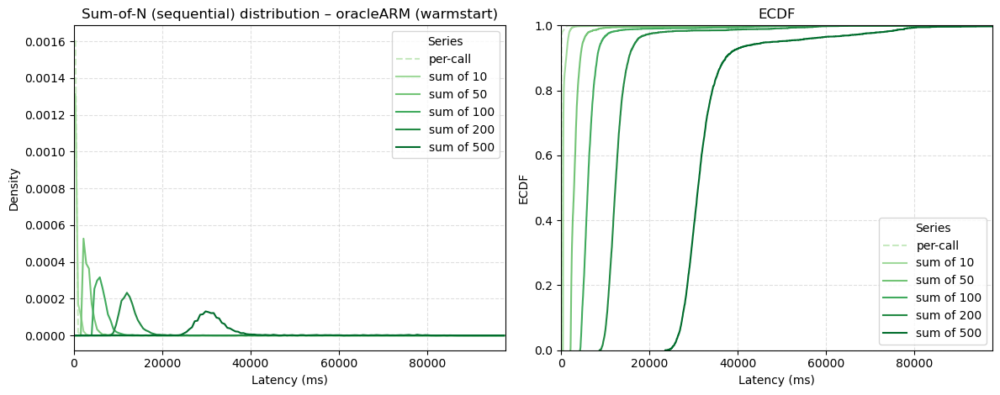

Provider deno | sum of 10: 4000 samples
Provider deno | sum of 50: 4000 samples
Provider deno | sum of 100: 4000 samples
Provider deno | sum of 200: 4000 samples
Provider deno | sum of 500: 4000 samples


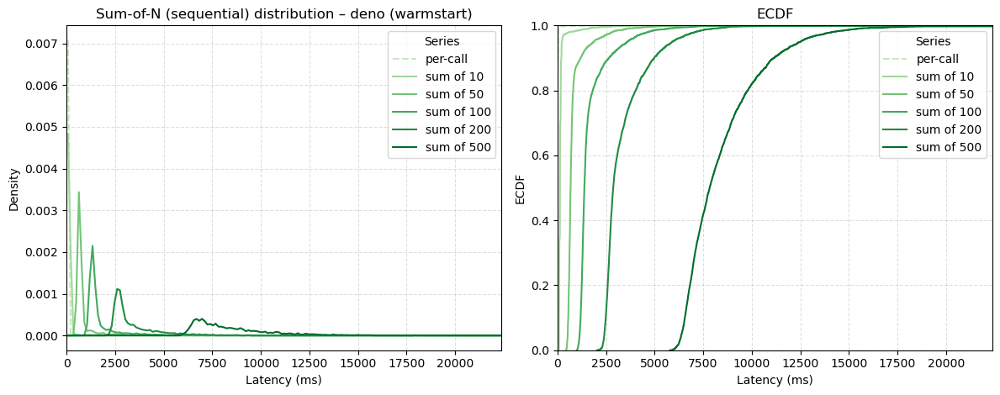

Provider cloudflare | sum of 10: 4000 samples
Provider cloudflare | sum of 50: 4000 samples
Provider cloudflare | sum of 100: 4000 samples
Provider cloudflare | sum of 200: 4000 samples
Provider cloudflare | sum of 500: 4000 samples


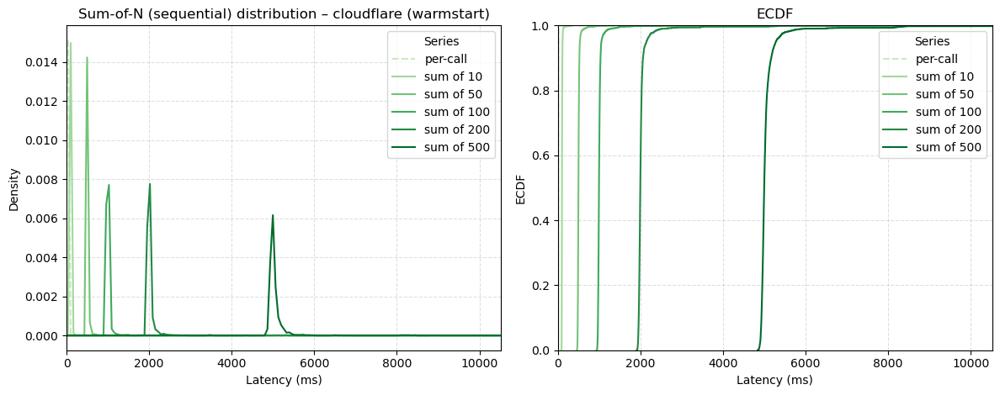

Provider flyio | sum of 10: 4000 samples
Provider flyio | sum of 50: 4000 samples
Provider flyio | sum of 100: 4000 samples
Provider flyio | sum of 200: 4000 samples
Provider flyio | sum of 500: 4000 samples


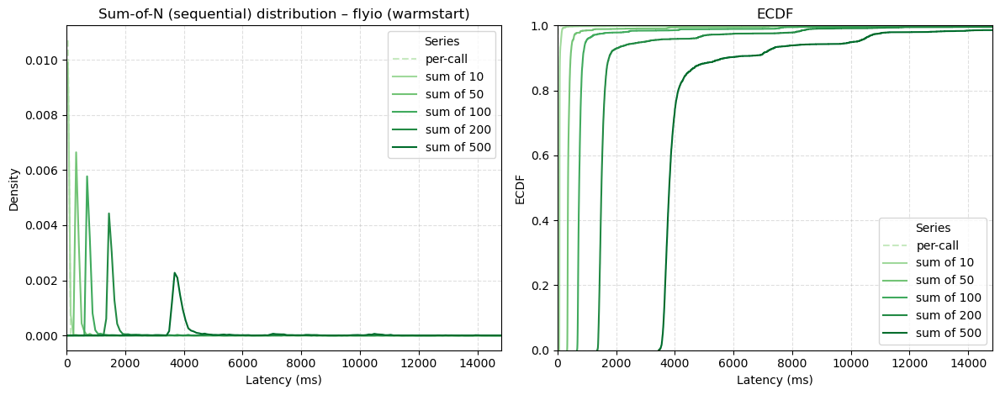

Provider fastly | sum of 10: 4000 samples
Provider fastly | sum of 50: 4000 samples
Provider fastly | sum of 100: 4000 samples
Provider fastly | sum of 200: 4000 samples
Provider fastly | sum of 500: 4000 samples


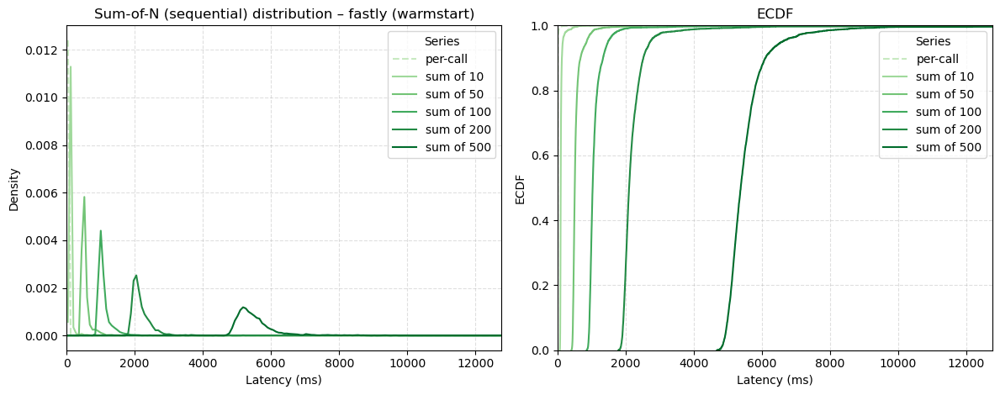

In [34]:
# Actual-data overlay: sum-of-N (sequential) distribution curves on one plot (per provider)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [10, 50, 100, 200, 500, 1000]
samples_per_n = 4000
rng = np.random.default_rng(42)

def density_line(samples: np.ndarray, bins: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    hist, edges = np.histogram(samples, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, hist

for provider in providers:
    if experiment == "warmstart" and provider != "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]
    elif experiment == "warmstart" and provider == "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        """
        params = [provider]

    df = pd.read_sql_query(query, cnx, params=params)
    latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()

    if latencies.empty:
        print(f"No latency data for provider {provider} ({experiment}).")
        continue

    max_n = max(n_values)
    sum_samples_for_xlim = rng.choice(latencies.values, size=(samples_per_n, max_n), replace=True).sum(axis=1)
    x_min = 0
    x_max_q = 95
    x_max = np.percentile(sum_samples_for_xlim, x_max_q)
    bins = np.linspace(x_min, x_max, 160)

    ramp = sns.color_palette("Greens", n_colors=len(n_values) + 1)
    base_color = ramp[1]
    line_colors = ramp[2:]

    fig, (ax_dist, ax_ecdf) = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
    x_base, y_base = density_line(latencies.values, bins)
    sns.lineplot(x=x_base, y=y_base, color=base_color, linestyle="--", label="per-call", ax=ax_dist)
    sns.ecdfplot(latencies.values, color=base_color, linestyle="--", label="per-call", ax=ax_ecdf)

    for n, color in zip(n_values, line_colors):
        draws = rng.choice(latencies.values, size=(samples_per_n, n), replace=True)
        sum_samples = draws.sum(axis=1)
        print(f"Provider {provider} | sum of {n}: {len(sum_samples)} samples")
        x_line, y_line = density_line(sum_samples, bins)
        sns.lineplot(x=x_line, y=y_line, color=color, label=f"sum of {n}", ax=ax_dist)
        sns.ecdfplot(sum_samples, color=color, label=f"sum of {n}", ax=ax_ecdf)

    ax_dist.set_title(f"Sum-of-N (sequential) distribution – {provider} ({experiment})")
    ax_dist.set_xlabel("Latency (ms)")
    ax_dist.set_ylabel("Density")
    ax_dist.grid(True, linestyle="--", alpha=0.4)
    ax_dist.set_xlim(x_min, x_max)
    ax_dist.legend(title="Series")

    ax_ecdf.set_title("ECDF")
    ax_ecdf.set_xlabel("Latency (ms)")
    ax_ecdf.set_ylabel("ECDF")
    ax_ecdf.grid(True, linestyle="--", alpha=0.4)
    ax_ecdf.set_xlim(x_min, x_max)
    ax_ecdf.legend(title="Series")

    fig.tight_layout()
    plt.show()

<notebook cell>:79: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()


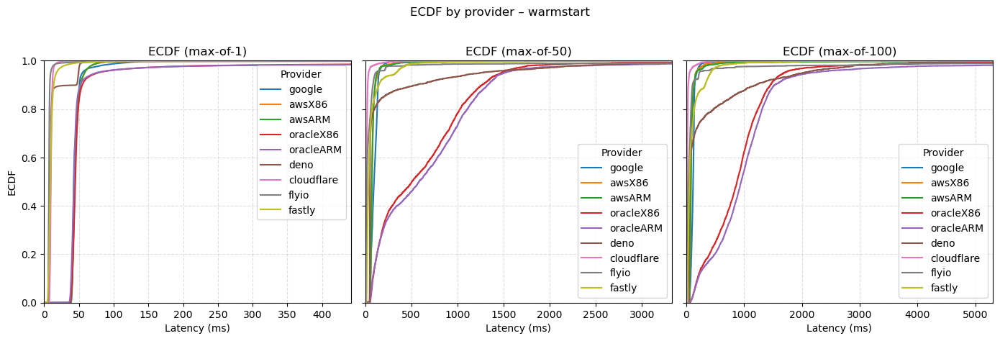

In [36]:
# ECDF comparison across providers for N=1, 50, 500 (max-of-N)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [1, 50, 100]
samples_per_n = 4000
rng = np.random.default_rng(42)

def load_latencies(provider: str, experiment: str) -> np.ndarray:
    if experiment == "warmstart" and provider != "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]
    elif experiment == "warmstart" and provider == "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        """
        params = [provider]

    df = pd.read_sql_query(query, cnx, params=params)
    lat = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna().values
    return lat

provider_latencies = {}
for provider in providers:
    lat = load_latencies(provider, experiment)
    if lat.size == 0:
        print(f"No latency data for provider {provider} ({experiment}).")
        continue
    provider_latencies[provider] = lat

if not provider_latencies:
    print("No latency data available for any provider.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
    for ax, n in zip(axes, n_values):
        samples_for_xlim = []
        for provider, lat in provider_latencies.items():
            if n == 1:
                samples = lat
            else:
                draws = rng.choice(lat, size=(samples_per_n, n), replace=True)
                samples = draws.max(axis=1)
            samples_for_xlim.append(samples)
            sns.ecdfplot(samples, ax=ax, label=provider)

        all_samples = np.concatenate(samples_for_xlim)
        x_min = 0
        x_max_q = 99.5
        x_max = np.percentile(all_samples, x_max_q)
        ax.set_xlim(x_min, x_max)
        ax.set_title(f"ECDF (max-of-{n})")
        ax.set_xlabel("Latency (ms)")
        ax.set_ylabel("ECDF")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend(title="Provider", ncol=1)

    fig.suptitle(f"ECDF by provider – {experiment}", y=1.02)
    fig.tight_layout()
    plt.show()

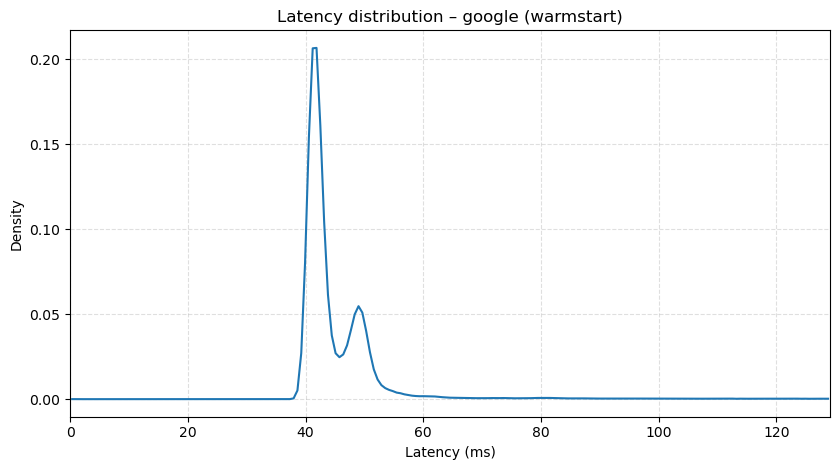

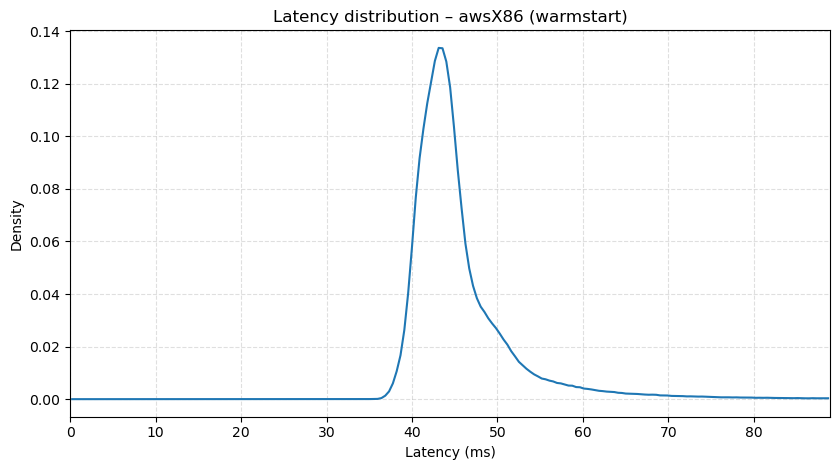

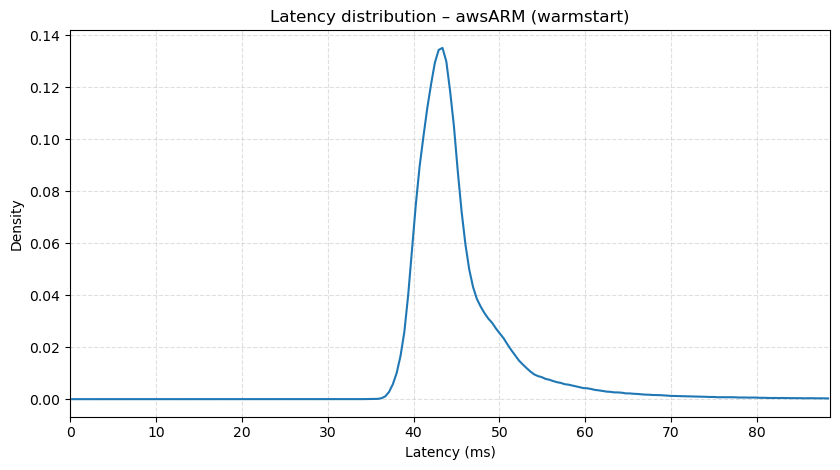

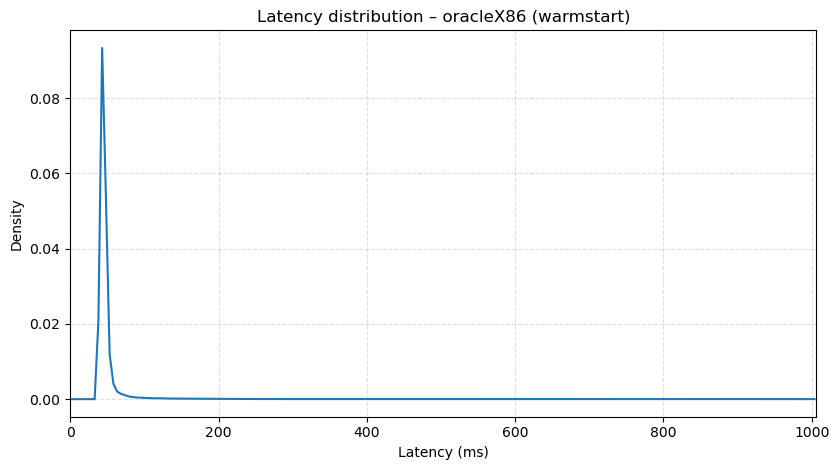

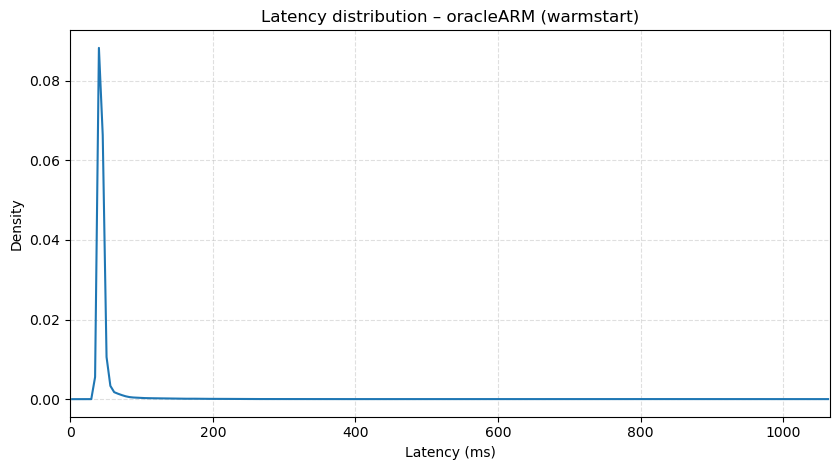

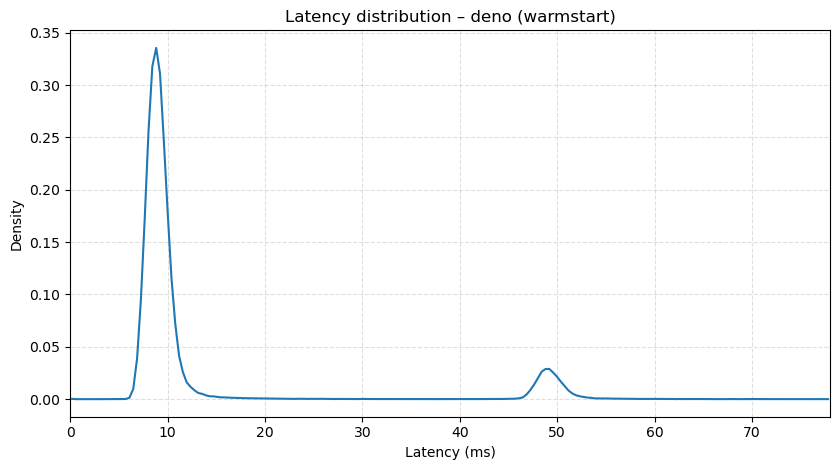

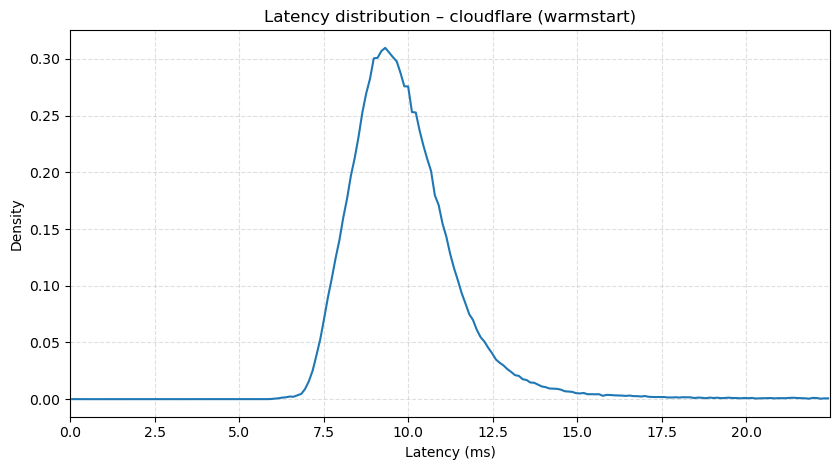

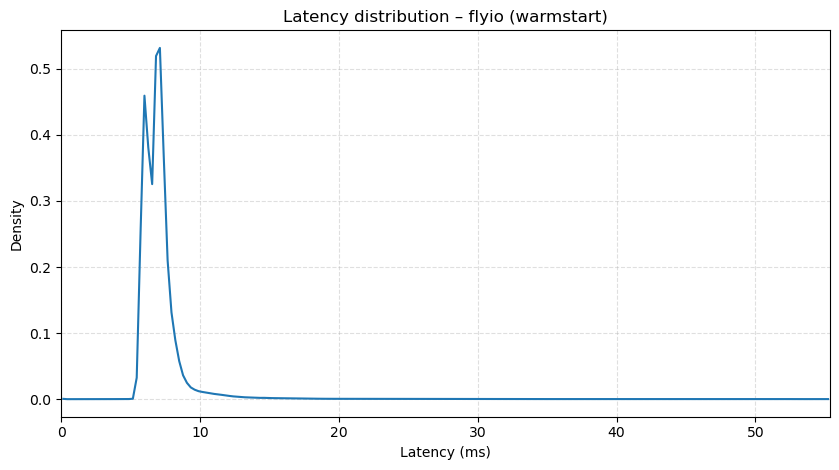

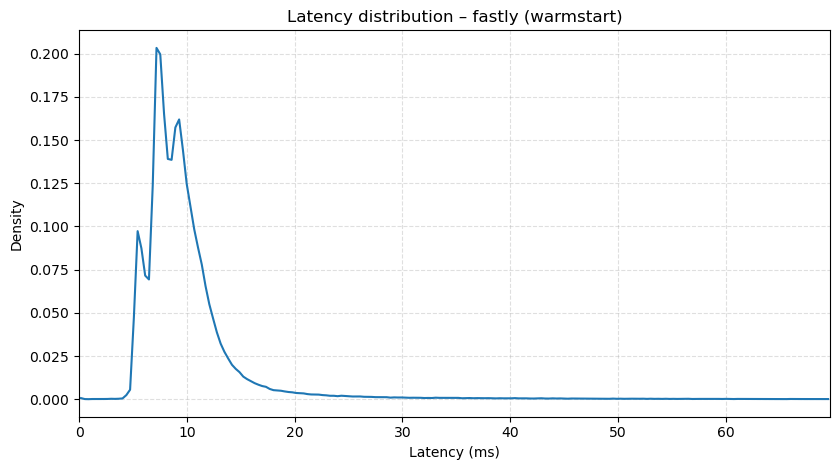

In [29]:
# Latency distribution per provider (one plot each)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
experiment = "warmstart"  # "warmstart" or "coldstart"

def density_line(samples: np.ndarray, bins: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    hist, edges = np.histogram(samples, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, hist

for provider in providers:
    if experiment == "warmstart" and provider != "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]
    elif experiment == "warmstart" and provider == "fastly":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        """
        params = [provider]

    df = pd.read_sql_query(query, cnx, params=params)
    latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()
    if latencies.empty:
        print(f"No latency data for provider {provider} ({experiment}).")
        continue

    x_min = 0
    x_max_q = 99.5
    x_max = np.percentile(latencies.values, x_max_q)
    bins = np.linspace(x_min, x_max, 200)

    x_line, y_line = density_line(latencies.values, bins)
    plt.figure(figsize=(8.5, 4.8))
    sns.lineplot(x=x_line, y=y_line, color="tab:blue")
    plt.title(f"Latency distribution – {provider} ({experiment})")
    plt.xlabel("Latency (ms)")
    plt.ylabel("Density")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.xlim(x_min, x_max)
    plt.tight_layout()
    plt.show()

Provider google | max of 1: 4000 samples
Provider google | max of 10: 4000 samples
Provider google | max of 50: 4000 samples
Provider google | max of 100: 4000 samples
Provider google | max of 200: 4000 samples
Provider google | max of 500: 4000 samples
Provider google | max of 1000: 4000 samples


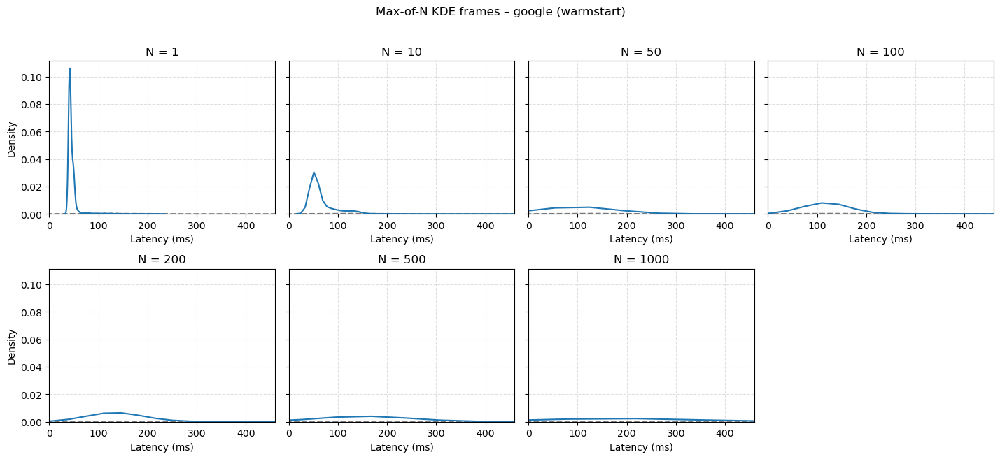

In [20]:
# Actual-data frames: max-of-N KDE shifts with N (per provider)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

provider = "google"  # <-- change this
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [1, 10, 50, 100, 200, 500, 1000]
samples_per_n = 4000
rng = np.random.default_rng(42)

if experiment == "warmstart" and provider != "fastly":
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
          AND cold_starts = 0
    """
    params = [provider]
elif experiment == "warmstart" and provider == "fastly":
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    params = [provider]
else:
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
    """
    params = [provider]

df = pd.read_sql_query(query, cnx, params=params)
latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()

if latencies.empty:
    print(f"No latency data for provider {provider} ({experiment}).")
else:
    max_n = max(n_values)
    max_samples_for_xlim = rng.choice(latencies.values, size=(samples_per_n, max_n), replace=True).max(axis=1)
    x_min = 0
    x_max_q = 95
    x_max = np.percentile(max_samples_for_xlim, x_max_q)

    max_samples_list = []
    for n in n_values:
        draws = rng.choice(latencies.values, size=(samples_per_n, n), replace=True)
        max_samples = draws.max(axis=1)
        max_samples_list.append(max_samples)
        print(f"Provider {provider} | max of {n}: {len(max_samples)} samples")

    fig_rows = 2
    fig_cols = int(np.ceil(len(n_values) / fig_rows))
    fig, axes = plt.subplots(fig_rows, fig_cols, figsize=(3.6 * fig_cols, 3.2 * fig_rows), sharey=True)
    axes = np.array(axes).ravel()

    for ax, n, max_samples in zip(axes, n_values, max_samples_list):
        sns.kdeplot(
            latencies.values,
            ax=ax,
            color="gray",
            linestyle="--",
            bw_adjust=1.0,
            label="per-call",
        )
        sns.kdeplot(
            max_samples,
            ax=ax,
            color="tab:blue",
            bw_adjust=1.0,
            label=f"max of {n}",
        )
        ax.set_title(f"N = {n}")
        ax.set_xlabel("Latency (ms)")
        ax.set_ylabel("Density")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.set_xlim(x_min, x_max)

    for ax in axes[len(n_values):]:
        ax.set_visible(False)

    fig.suptitle(f"Max-of-N KDE frames – {provider} ({experiment})", y=1.02)
    fig.tight_layout()
    plt.show()

In [ ]:
# Actual-data overlay: max-of-N KDEs on one plot (per provider)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

provider = "google"  # <-- change this
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [1, 10, 50, 100, 200, 500, 1000]
samples_per_n = 4000
rng = np.random.default_rng(42)

if experiment == "warmstart" and provider != "fastly":
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
          AND cold_starts = 0
    """
    params = [provider]
elif experiment == "warmstart" and provider == "fastly":
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    params = [provider]
else:
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
    """
    params = [provider]

df = pd.read_sql_query(query, cnx, params=params)
latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()

if latencies.empty:
    print(f"No latency data for provider {provider} ({experiment}).")
else:
    plt.figure(figsize=(8.5, 4.8))
    sns.kdeplot(
        latencies.values,
        color="gray",
        linestyle="--",
        bw_adjust=1.0,
        label="per-call",
    )
    for n in n_values:
        draws = rng.choice(latencies.values, size=(samples_per_n, n), replace=True)
        max_samples = draws.max(axis=1)
        print(f"Provider {provider} | max of {n}: {len(max_samples)} samples")
        sns.kdeplot(
            max_samples,
            bw_adjust=1.0,
            label=f"max of {n}",
        )

    plt.title(f"Max-of-N KDE overlay – {provider} ({experiment})")
    plt.xlabel("Latency (ms)")
    plt.ylabel("Density")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.legend(title="Series")
    plt.tight_layout()
    plt.show()

Provider awsX86 | max of 1: 4000 samples
Provider awsX86 | max of 10: 4000 samples
Provider awsX86 | max of 50: 4000 samples
Provider awsX86 | max of 100: 4000 samples
Provider awsX86 | max of 200: 4000 samples
Provider awsX86 | max of 500: 4000 samples
Provider awsX86 | max of 1000: 4000 samples


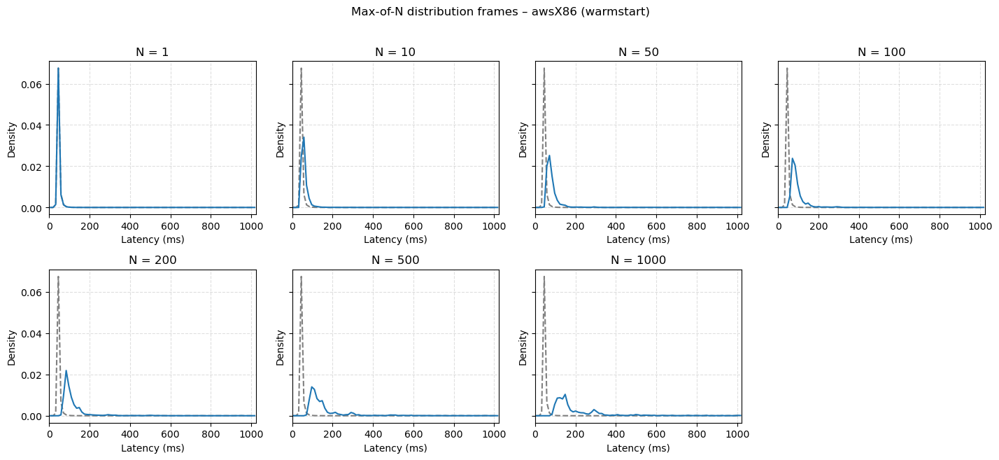

In [19]:
# Actual-data frames: max-of-N distribution shifts with N (per provider)
import numpy as np
import matplotlib.pyplot as plt

provider = "awsX86"  # <-- change this
experiment = "warmstart"  # "warmstart" or "coldstart"
n_values = [1, 10, 50, 100, 200, 500, 1000]
samples_per_n = 4000
rng = np.random.default_rng(42)

if experiment == "warmstart" and provider != "fastly":
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
          AND cold_starts = 0
    """
    params = [provider]
elif experiment == "warmstart" and provider == "fastly":
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    params = [provider]
else:
    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
    """
    params = [provider]

df = pd.read_sql_query(query, cnx, params=params)
latencies = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()

if latencies.empty:
    print(f"No latency data for provider {provider} ({experiment}).")
else:
    max_n = max(n_values)
    max_samples_for_xlim = rng.choice(latencies.values, size=(samples_per_n, max_n), replace=True).max(axis=1)
    x_min = 0
    x_max_q = 95
    x_max = np.percentile(max_samples_for_xlim, x_max_q)
    bins = np.linspace(x_min, x_max, 80)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    def density(samples):
        hist, _ = np.histogram(samples, bins=bins, density=True)
        return hist

    densities = []
    for n in n_values:
        draws = rng.choice(latencies.values, size=(samples_per_n, n), replace=True)
        max_samples = draws.max(axis=1)
        densities.append(density(max_samples))
        print(f"Provider {provider} | max of {n}: {len(max_samples)} samples")

    base_density = density(latencies.values)

    fig_rows = 2
    fig_cols = int(np.ceil(len(n_values) / fig_rows))
    fig, axes = plt.subplots(fig_rows, fig_cols, figsize=(3.6 * fig_cols, 3.2 * fig_rows), sharey=True)
    axes = np.array(axes).ravel()

    for ax, n, dens in zip(axes, n_values, densities):
        ax.plot(bin_centers, base_density, color="gray", linestyle="--", label="per-call")
        ax.plot(bin_centers, dens, color="tab:blue", label=f"max of {n}")
        ax.set_title(f"N = {n}")
        ax.set_xlabel("Latency (ms)")
        ax.set_ylabel("Density")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.set_xlim(x_min, x_max)

    for ax in axes[len(n_values):]:
        ax.set_visible(False)

    fig.suptitle(f"Max-of-N distribution frames – {provider} ({experiment})", y=1.02)
    fig.tight_layout()
    plt.show()